Device: cuda
GPU: Tesla T4

Loading /kaggle/input/datasets/himadri07/ciciot2023/CICIOT23/train/train.csv
Sampling mode=first, requested rows=580,000
Loaded: (580000, 47)

Loading /kaggle/input/datasets/himadri07/ciciot2023/CICIOT23/validation/validation.csv
Sampling mode=first, requested rows=60,000
Loaded: (60000, 47)

Loading /kaggle/input/datasets/himadri07/ciciot2023/CICIOT23/test/test.csv
Sampling mode=first, requested rows=60,000
Loaded: (60000, 47)

Target column: label
TRAIN: 580,000 -> 578,591 rows; duplicates removed=1,409; missing labels removed=0
VALIDATION: 60,000 -> 59,983 rows; duplicates removed=17; missing labels removed=0
TEST: 60,000 -> 59,989 rows; duplicates removed=11; missing labels removed=0

Feature columns removed:
None
Constant feature columns removed: ['ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'IRC', 'DHCP']

Training class counts after rare-label grouping:
DDoS-ICMP_Flood            89546
DDoS-PSHACK_Flood          50560
DDoS-RSTFINFlood      

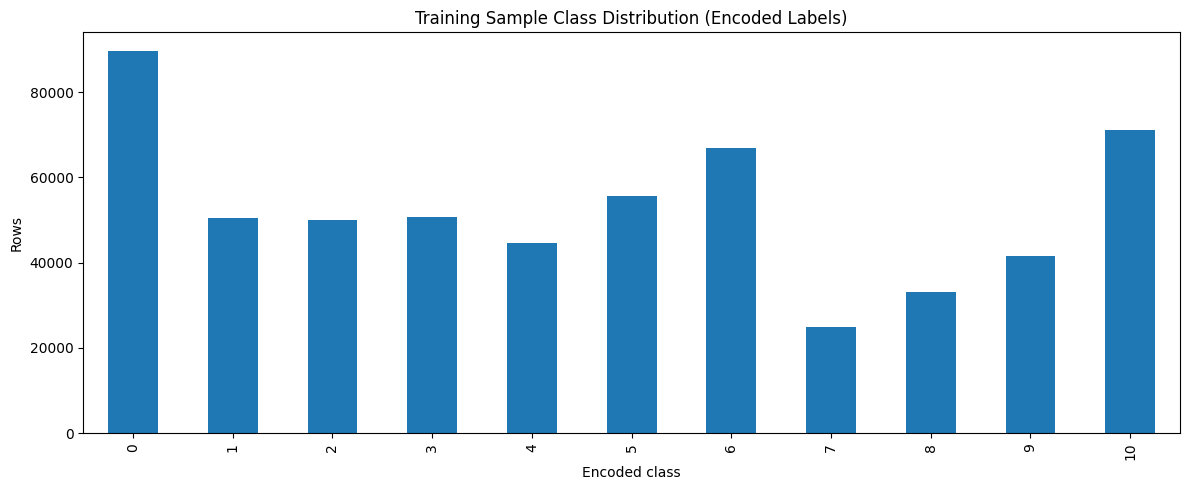


Model parameters: 55131
Class names: ['DDoS-ICMP_Flood', 'DDoS-PSHACK_Flood', 'DDoS-RSTFINFlood', 'DDoS-SYN_Flood', 'DDoS-SynonymousIP_Flood', 'DDoS-TCP_Flood', 'DDoS-UDP_Flood', 'DoS-SYN_Flood', 'DoS-TCP_Flood', 'DoS-UDP_Flood', 'Others']
Epoch 001/50 | Train loss=0.55998, acc=0.79721, macro-F1=0.73237 | Val loss=0.45751, acc=0.80698, macro-F1=0.74912
Epoch 002/50 | Train loss=0.43739, acc=0.82503, macro-F1=0.77783 | Val loss=0.42059, acc=0.81020, macro-F1=0.75564
Epoch 003/50 | Train loss=0.40082, acc=0.84741, macro-F1=0.80915 | Val loss=0.40383, acc=0.80069, macro-F1=0.73780
Epoch 004/50 | Train loss=0.32555, acc=0.88609, macro-F1=0.85908 | Val loss=0.34615, acc=0.81918, macro-F1=0.76802
Epoch 005/50 | Train loss=0.25401, acc=0.92051, macro-F1=0.90131 | Val loss=0.50198, acc=0.72249, macro-F1=0.63950
Epoch 006/50 | Train loss=0.20705, acc=0.94178, macro-F1=0.92749 | Val loss=0.18375, acc=0.95565, macro-F1=0.94051
Epoch 007/50 | Train loss=0.18077, acc=0.95061, macro-F1=0.93808 | Va

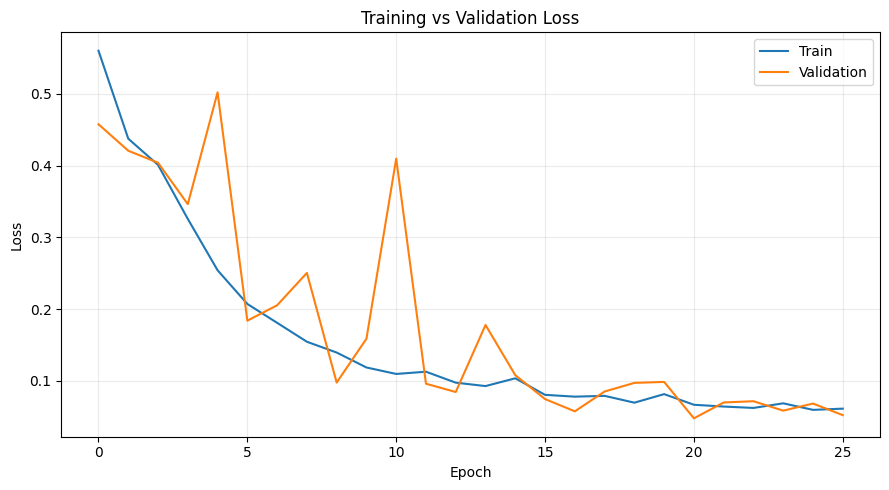

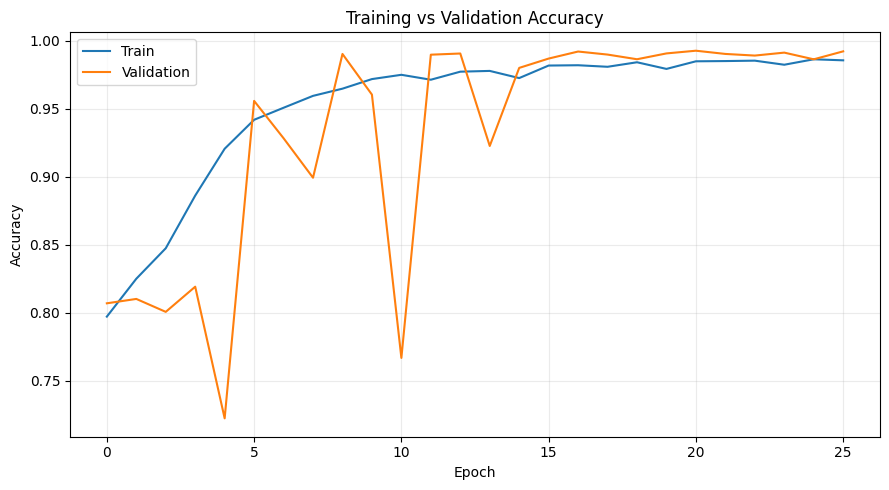

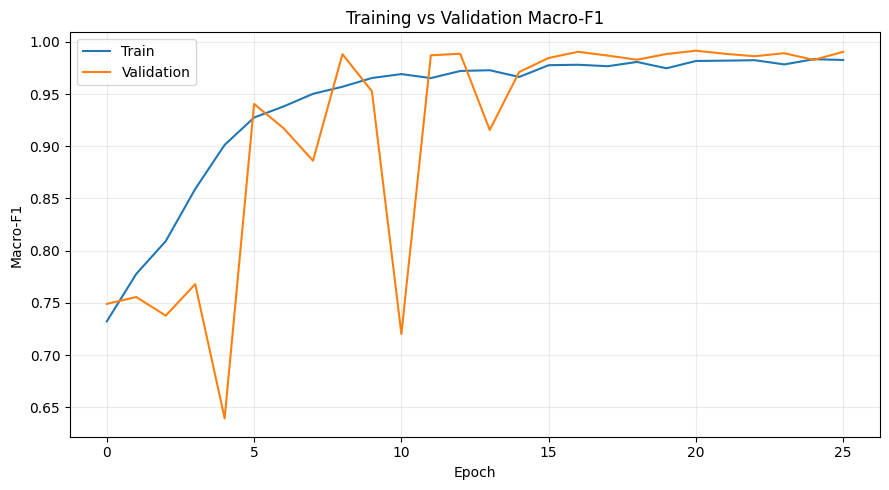

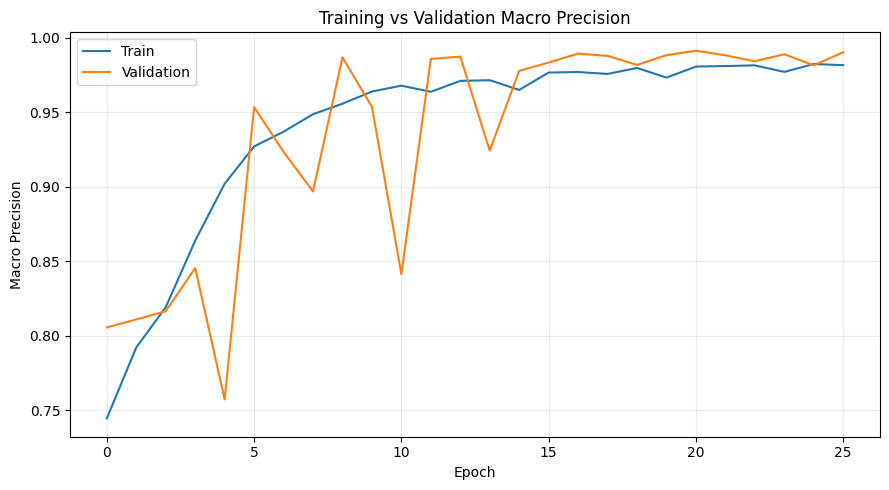

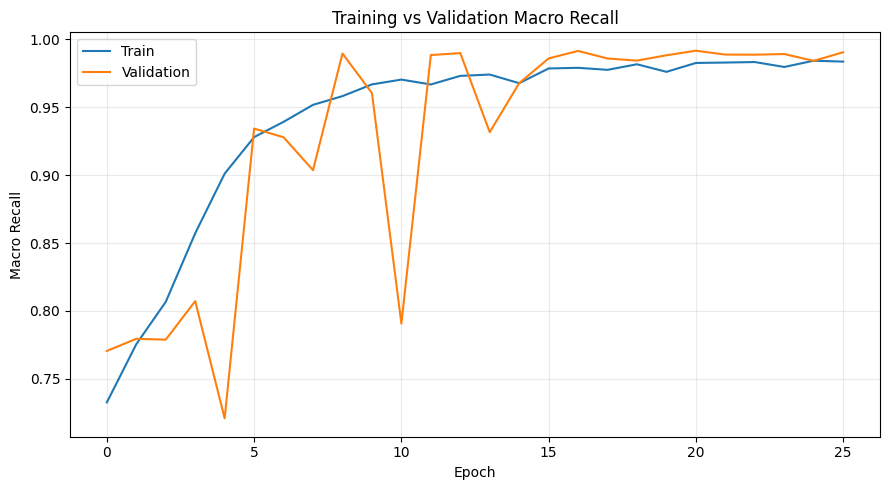

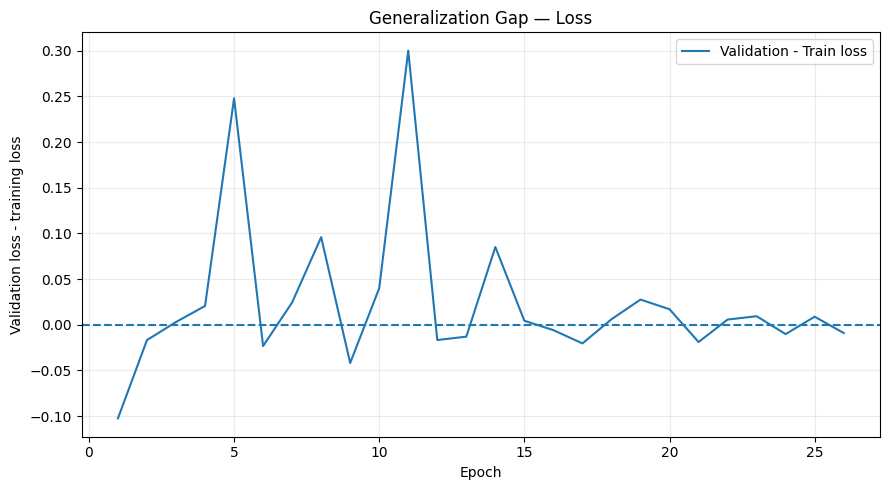

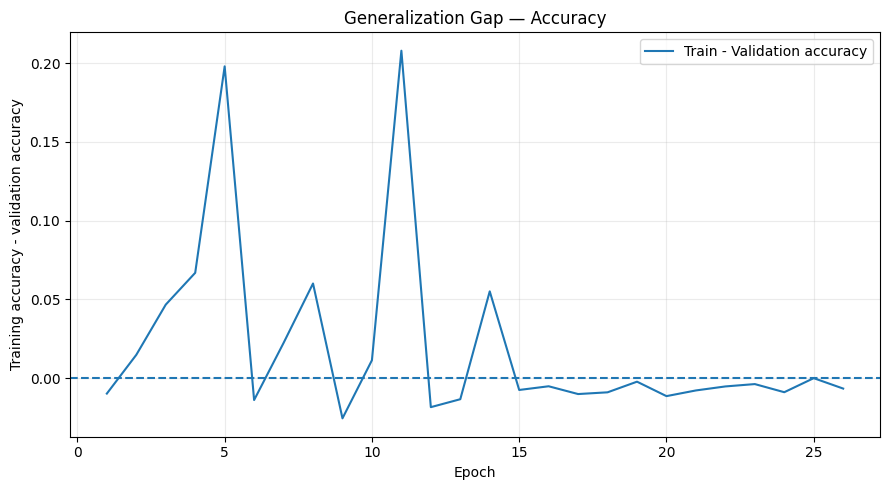

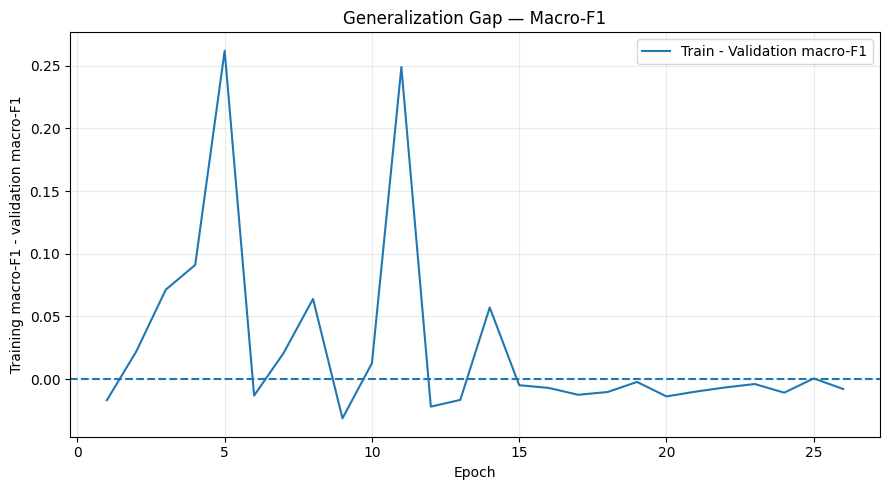

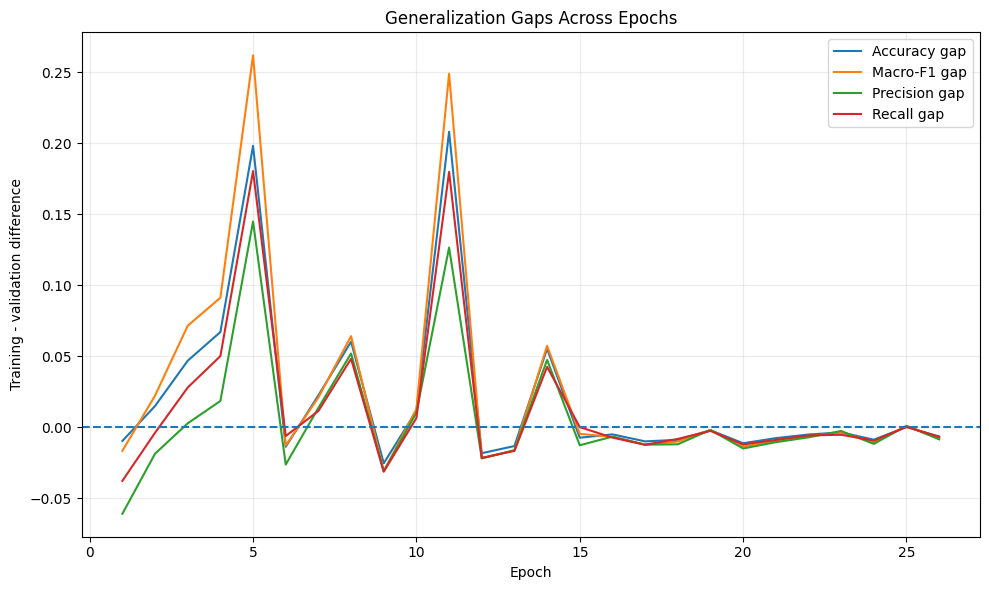


========== TEST RESULTS ==========
test_accuracy: 0.992499
test_macro_precision: 0.991210
test_macro_recall: 0.991830
test_macro_f1: 0.991453
test_weighted_f1: 0.992488

Classification Report:
                          precision    recall  f1-score   support

        DDoS-ICMP_Flood    1.00000   0.99850   0.99925      9359
      DDoS-PSHACK_Flood    1.00000   0.99829   0.99914      5262
       DDoS-RSTFINFlood    0.99980   1.00000   0.99990      5079
         DDoS-SYN_Flood    0.99484   0.95739   0.97575      5233
DDoS-SynonymousIP_Flood    0.96530   0.99703   0.98091      4716
         DDoS-TCP_Flood    0.99788   0.99384   0.99586      5685
         DDoS-UDP_Flood    0.98980   0.99639   0.99308      6917
          DoS-SYN_Flood    0.97814   0.99425   0.98613      2610
          DoS-TCP_Flood    0.99066   0.99472   0.99269      3411
          DoS-UDP_Flood    0.99473   0.98318   0.98892      4222
                 Others    0.99216   0.99653   0.99434      7495

               accuracy

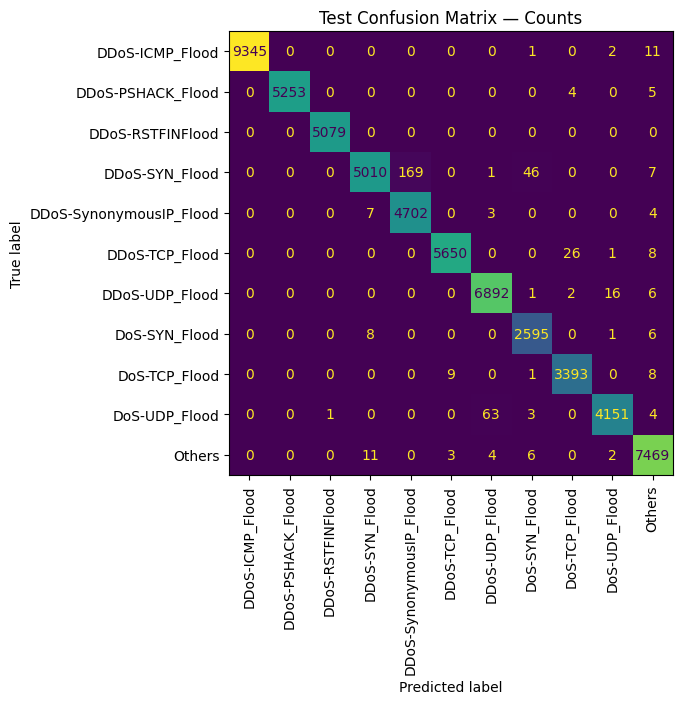

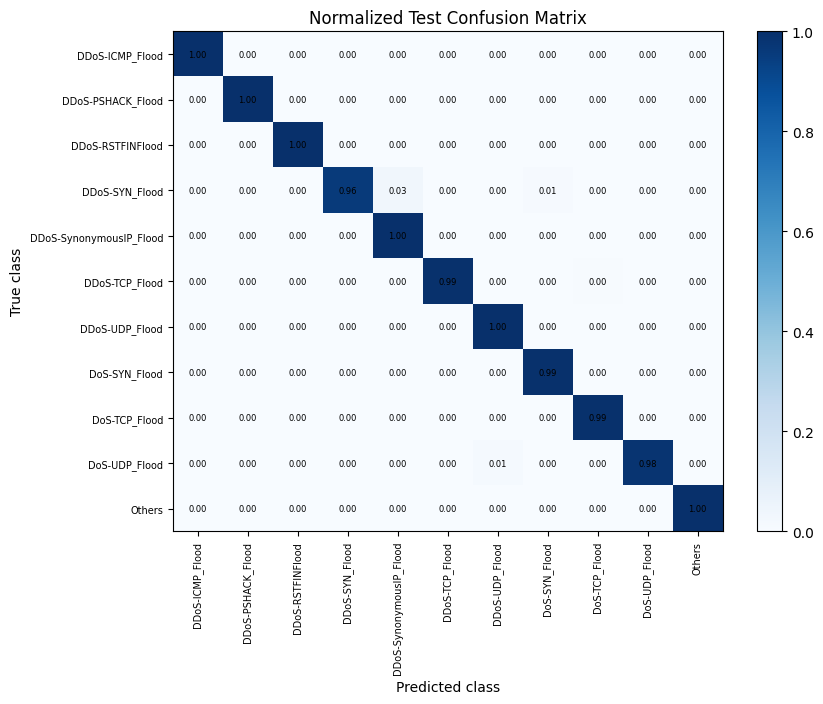

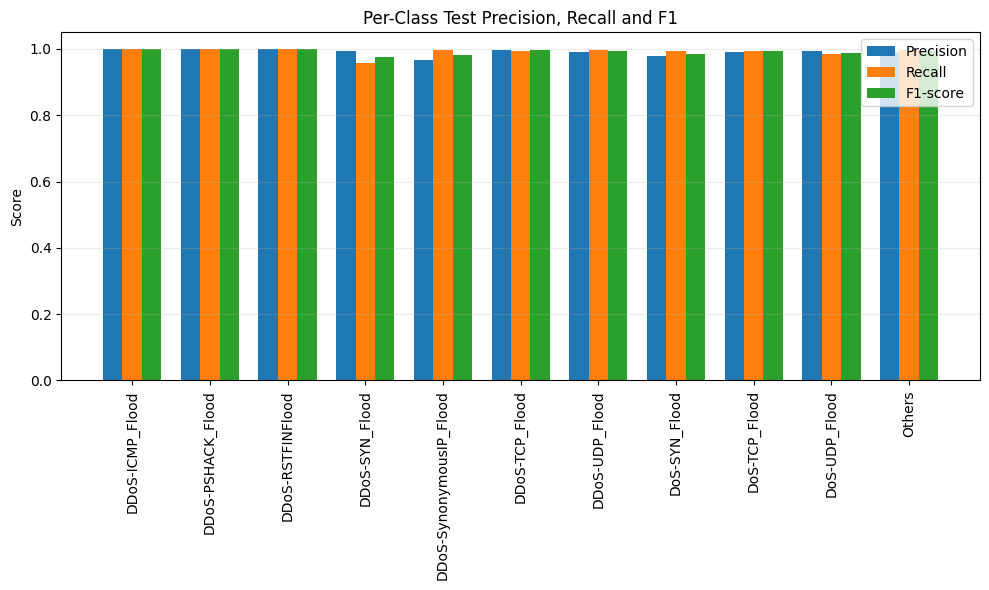

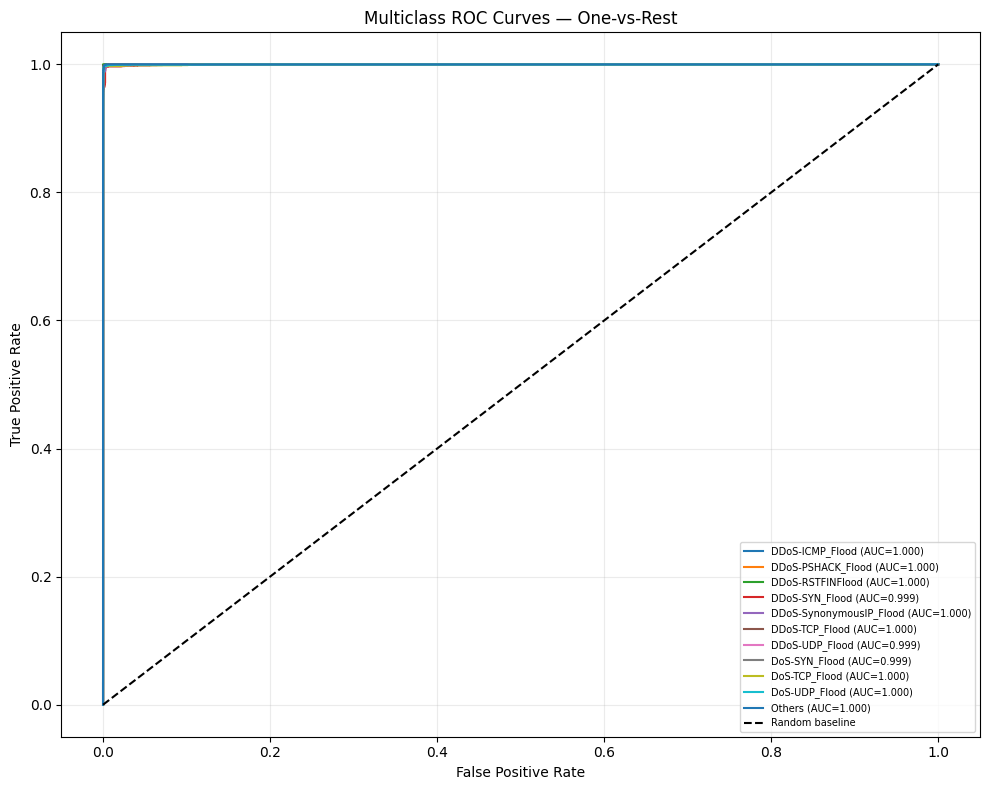

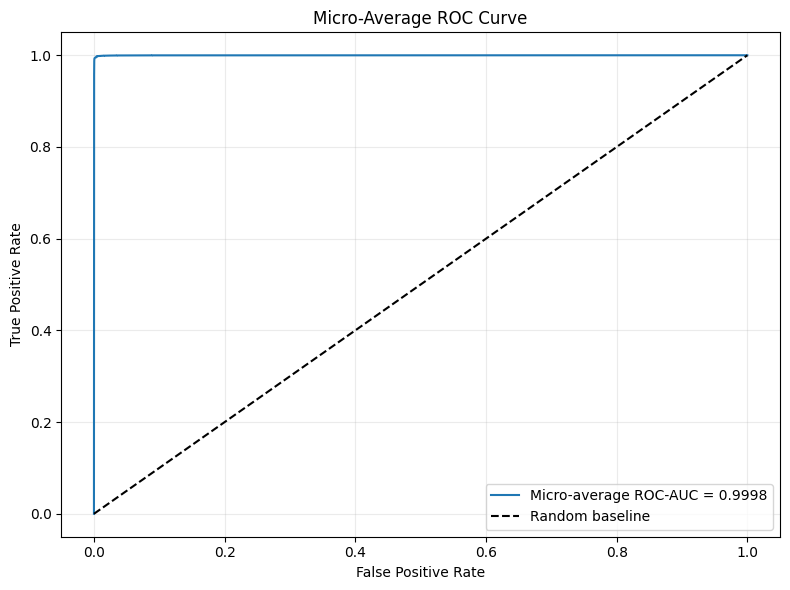

Micro-average ROC-AUC: 0.999750


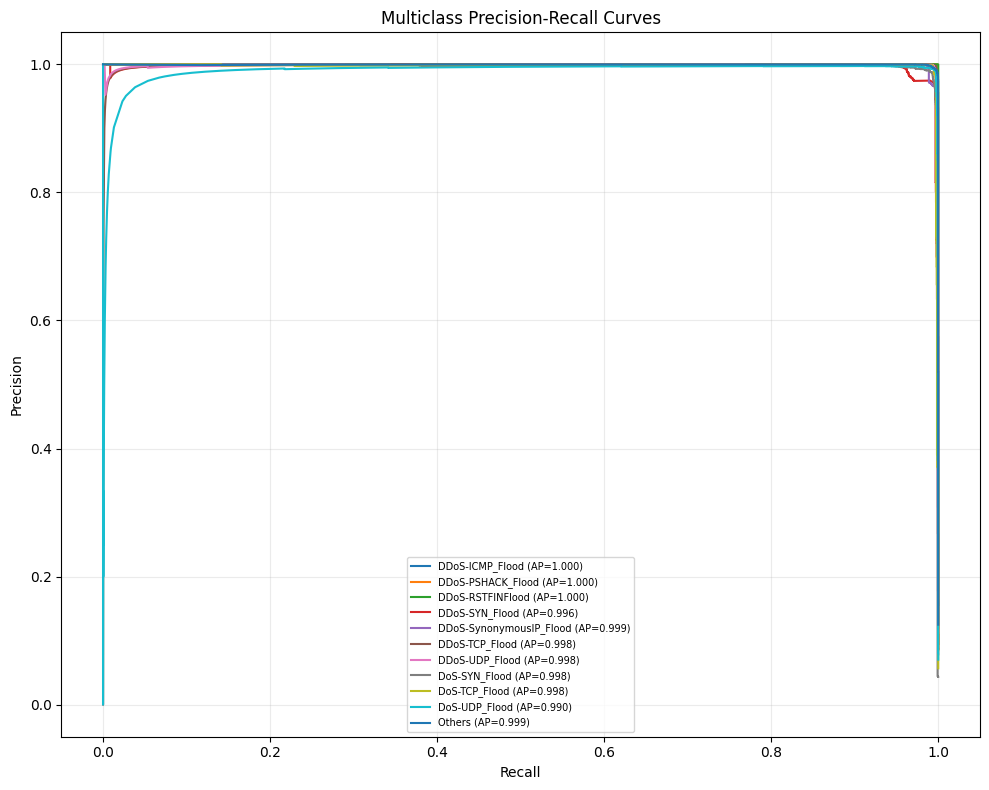

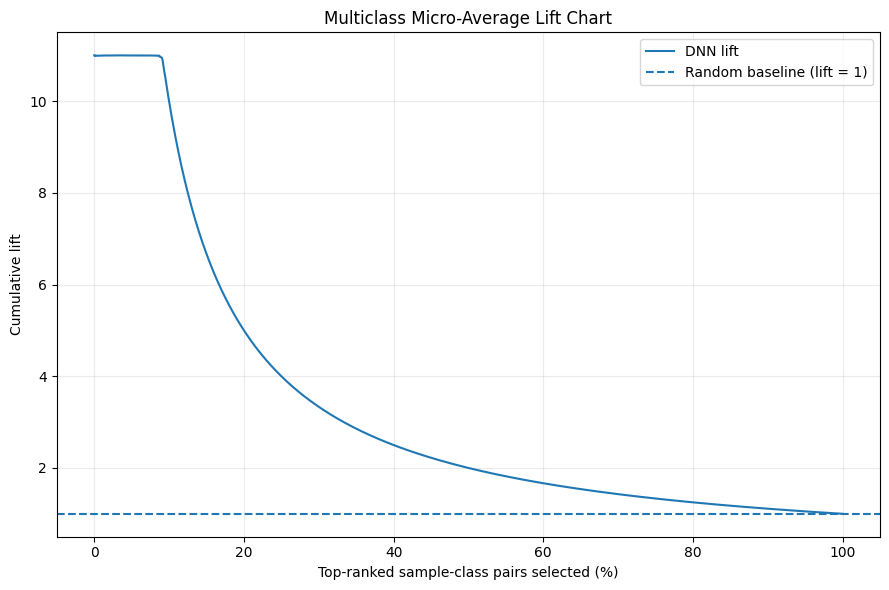

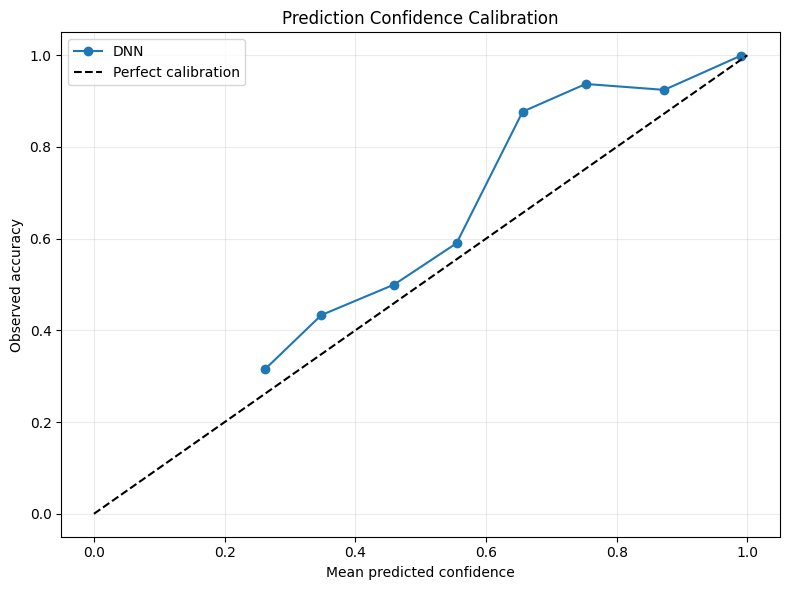

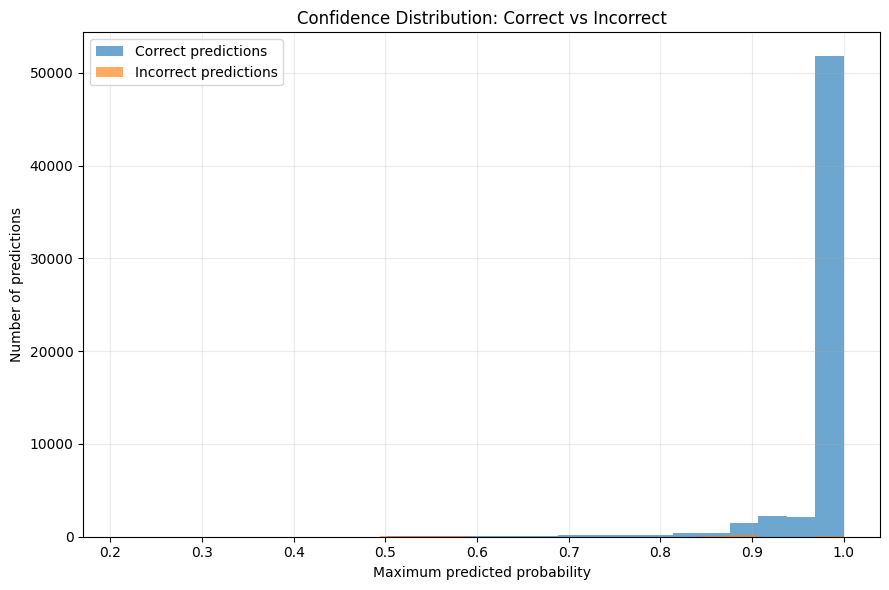

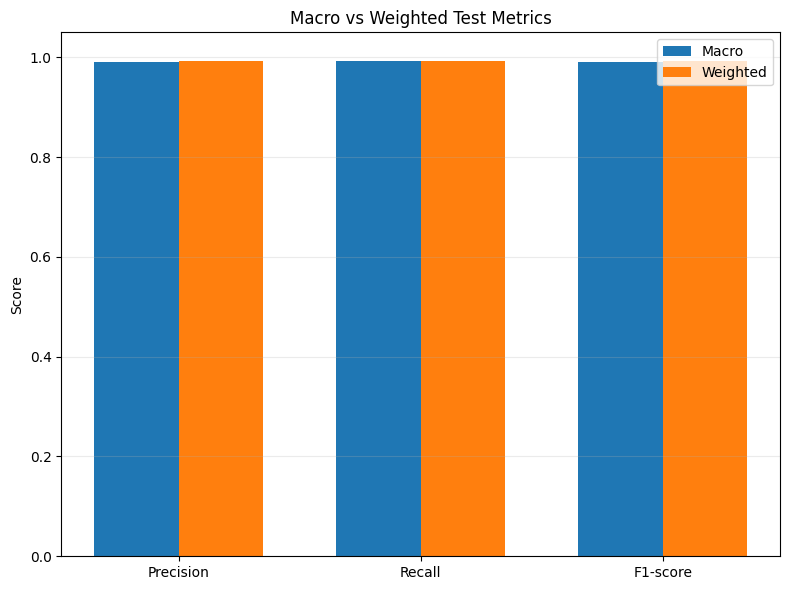

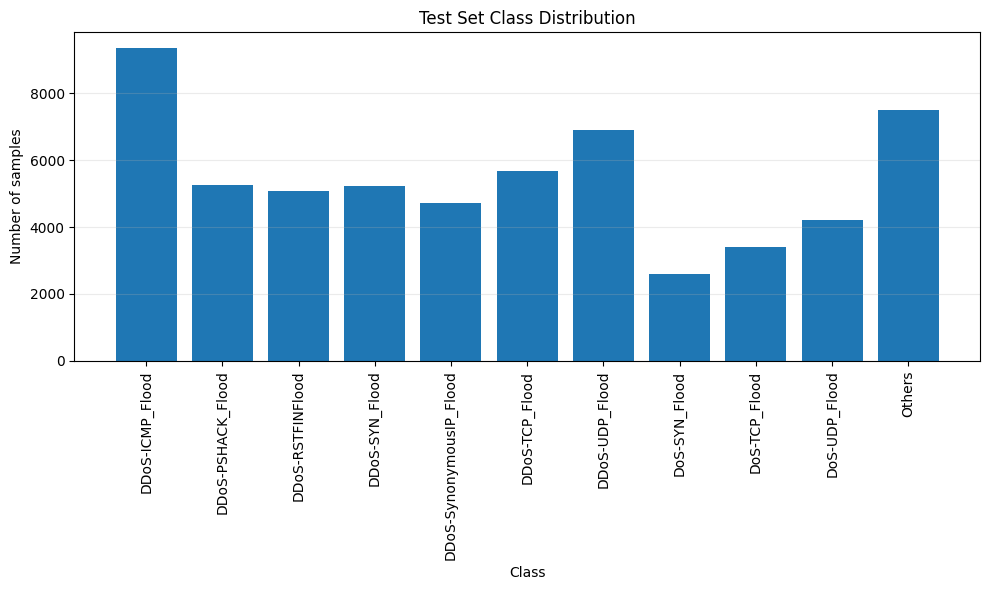


========== [XAI 1/3] RUNNING SHAP GRADIENT EXPLAINER ==========


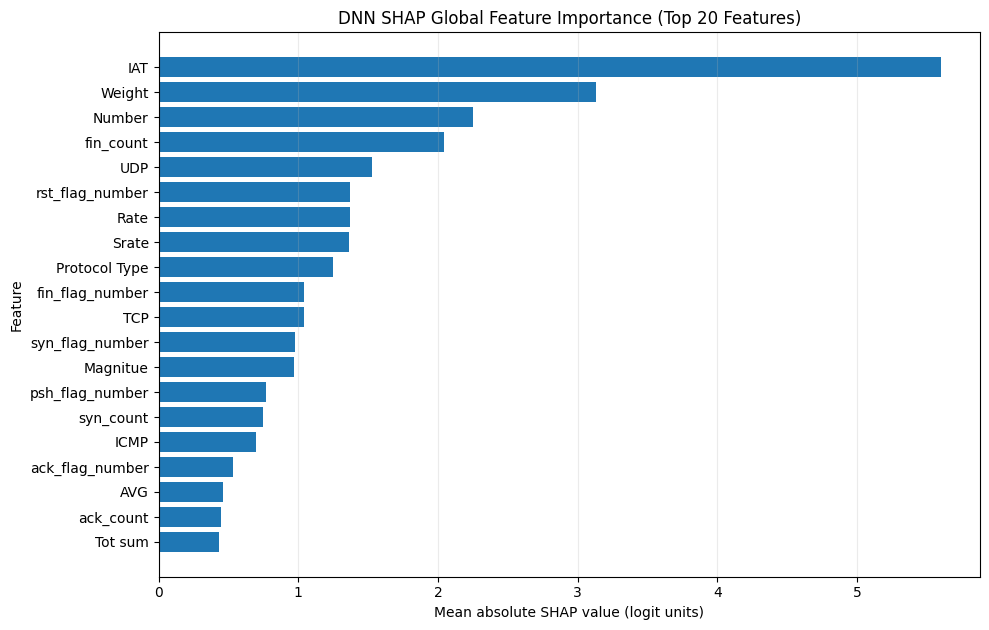

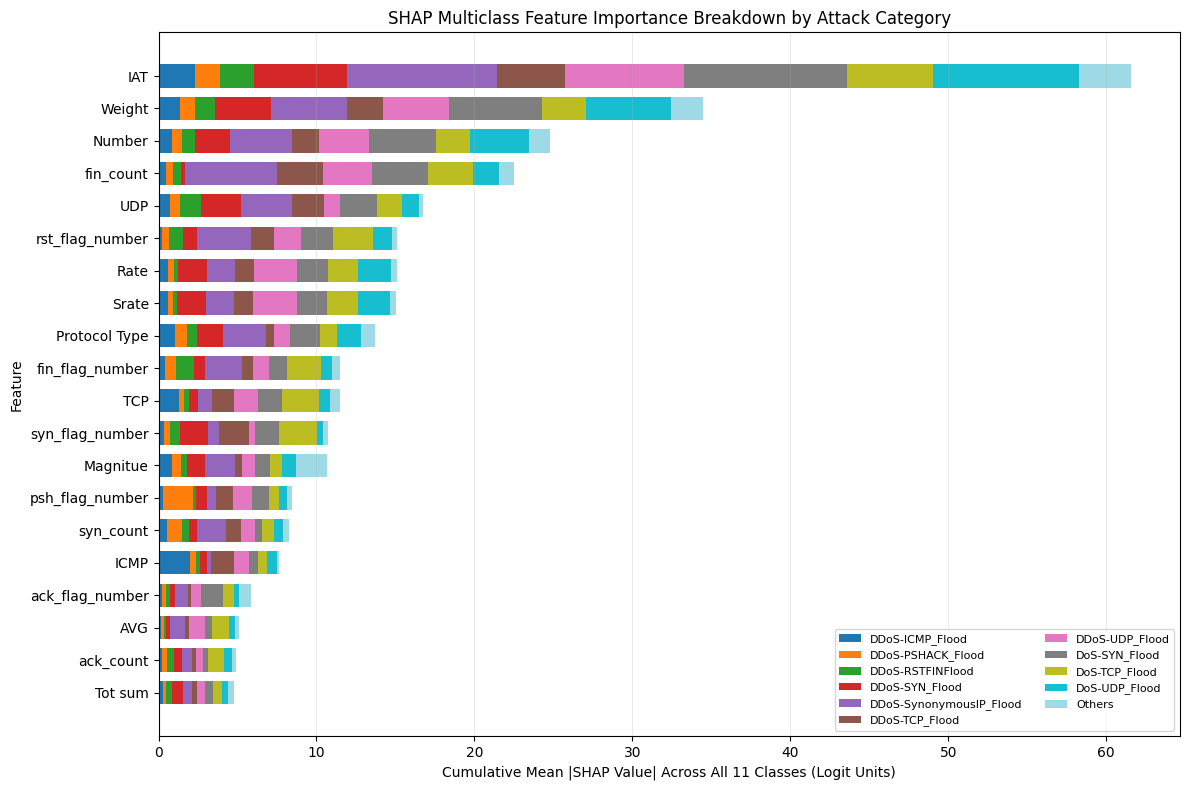

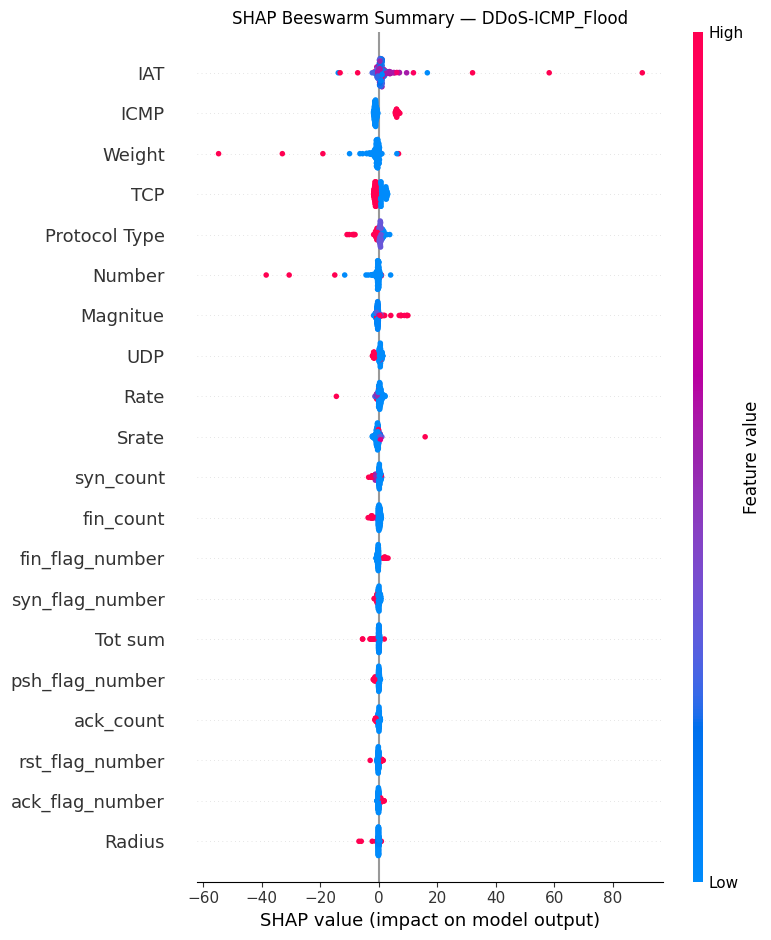

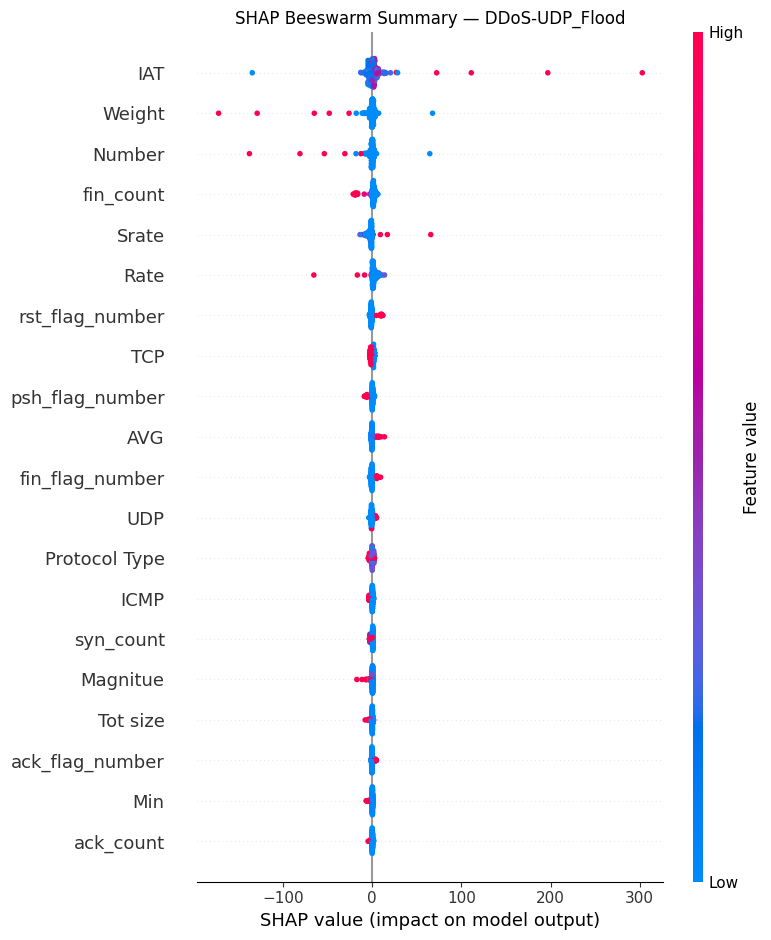

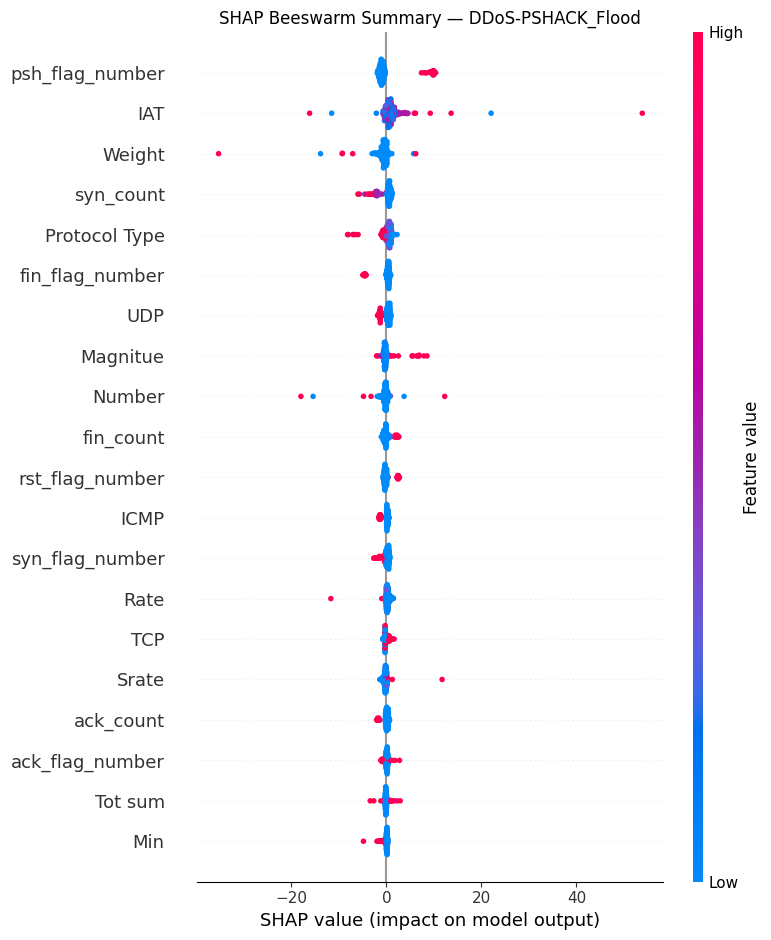

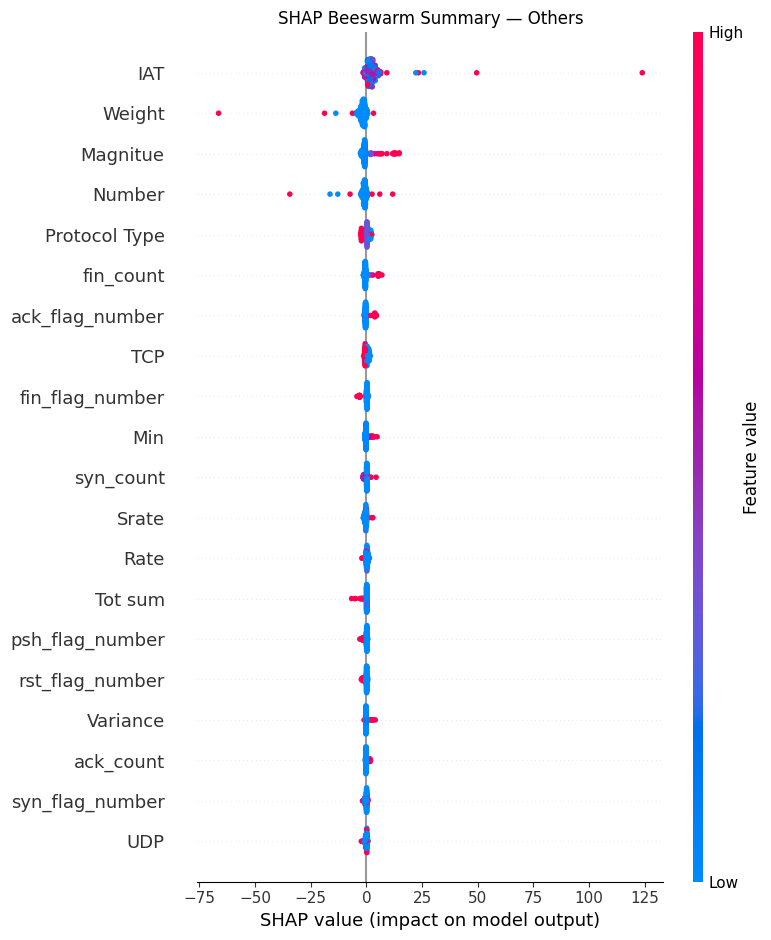

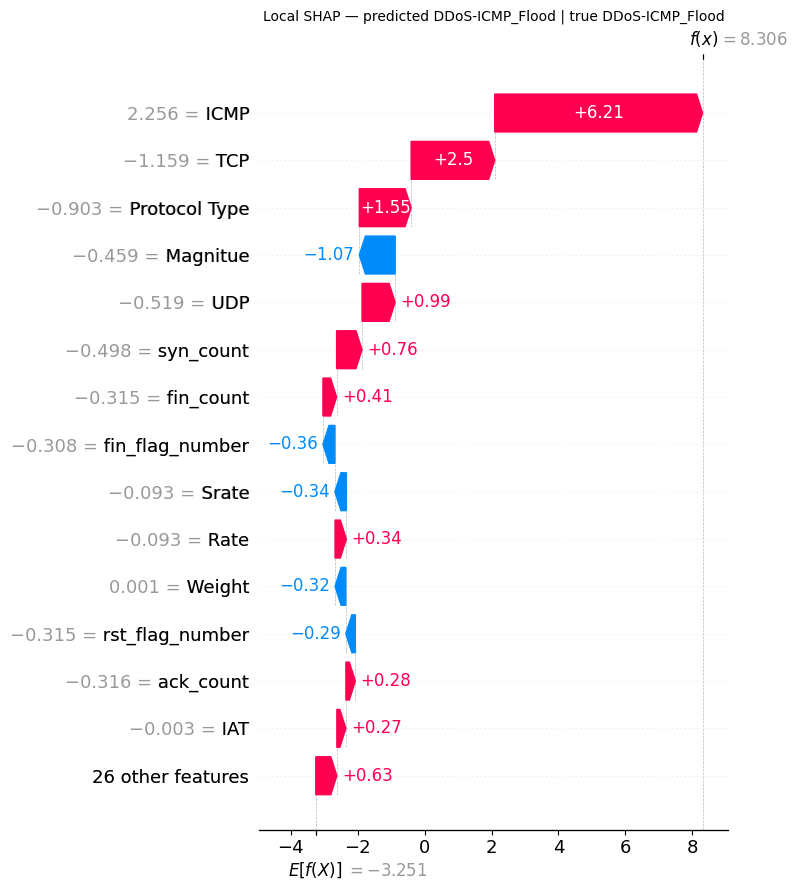

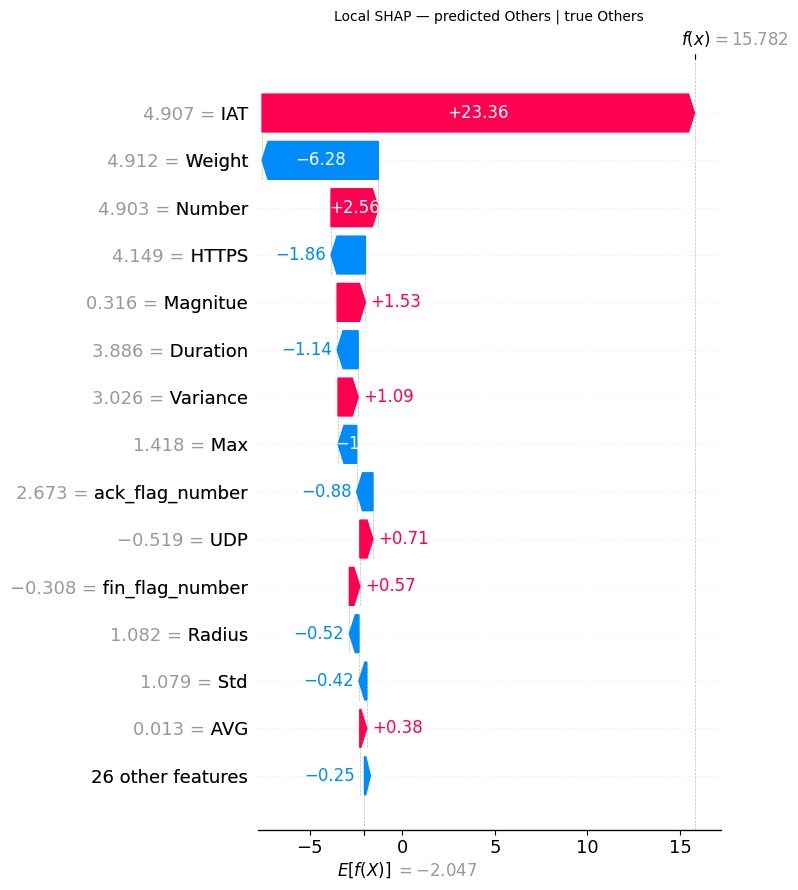

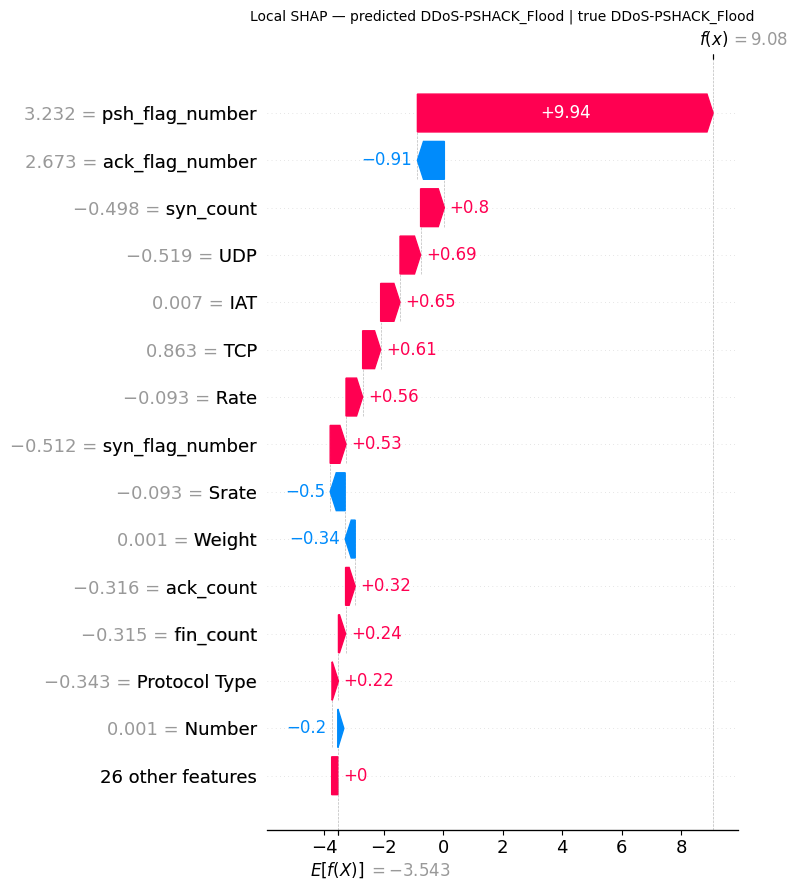

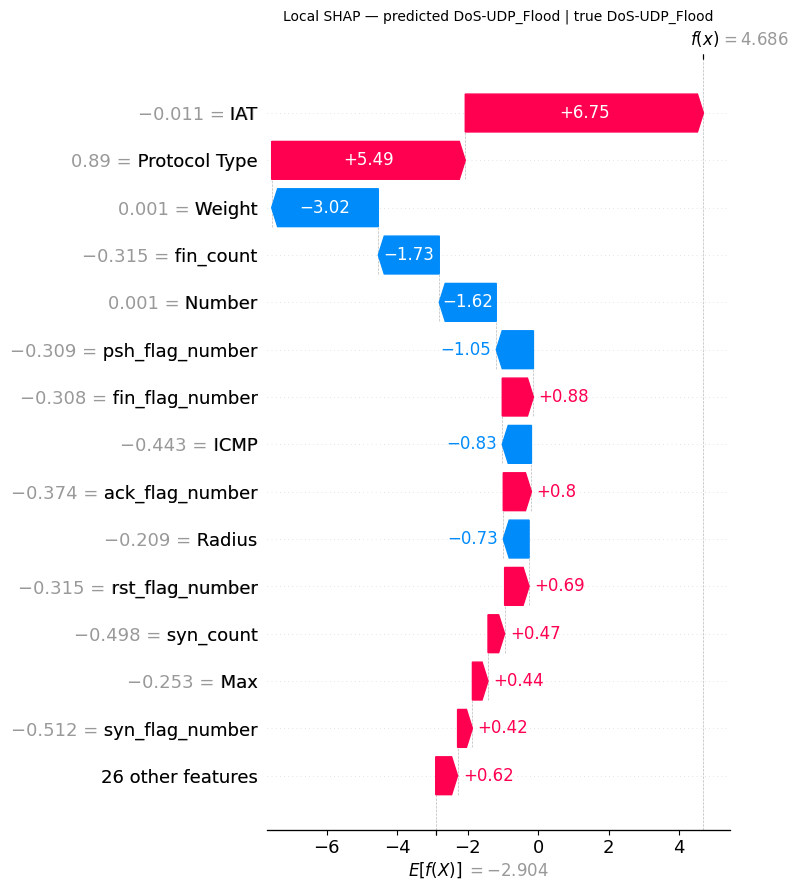

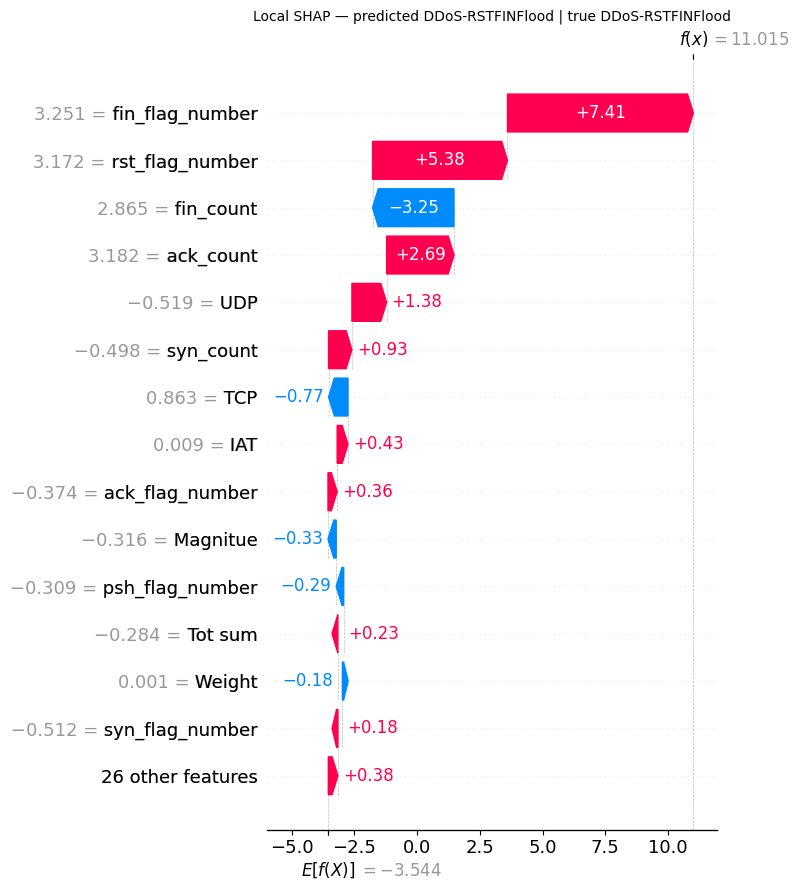

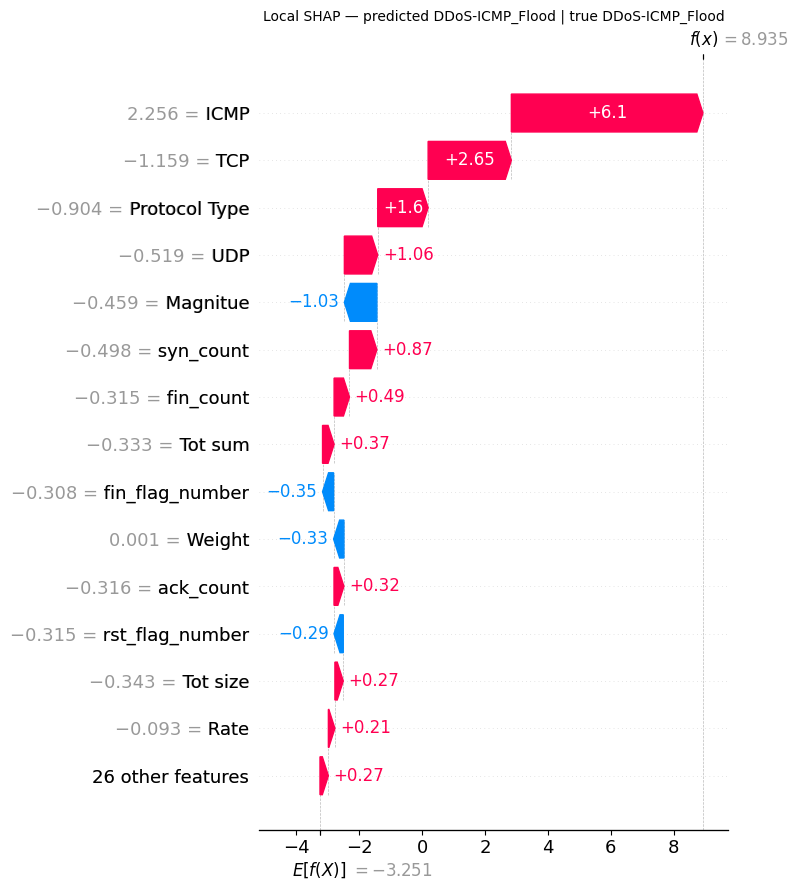


========== [XAI 2/3] RUNNING LOGIT-ALIGNED LIME TABULAR EXPLAINER ==========


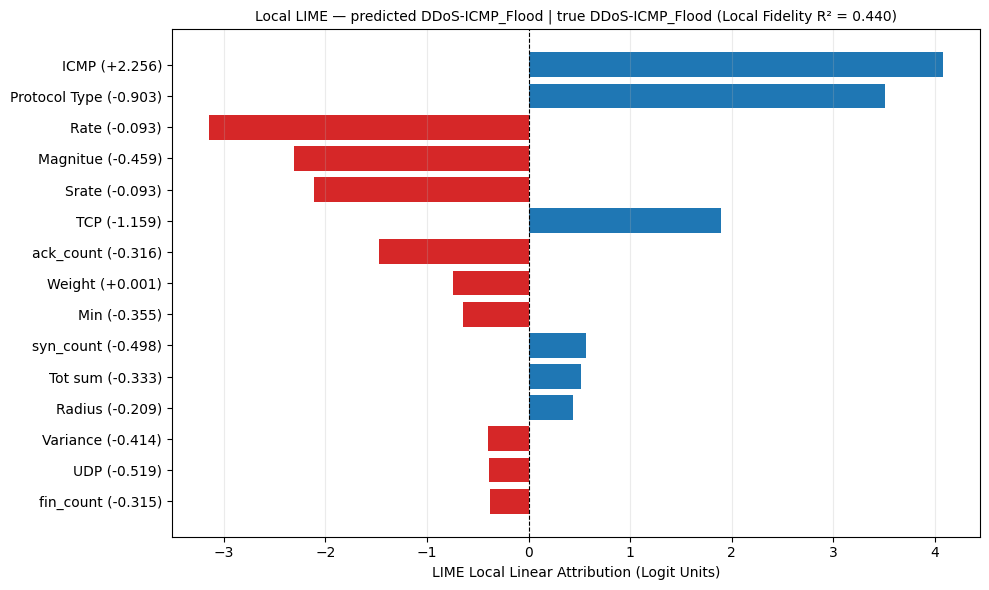

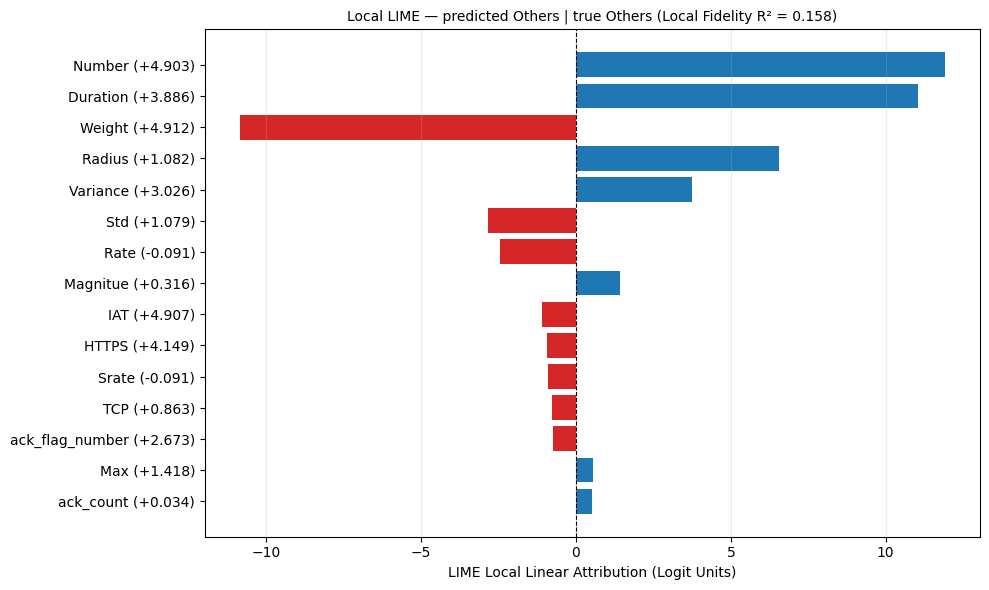

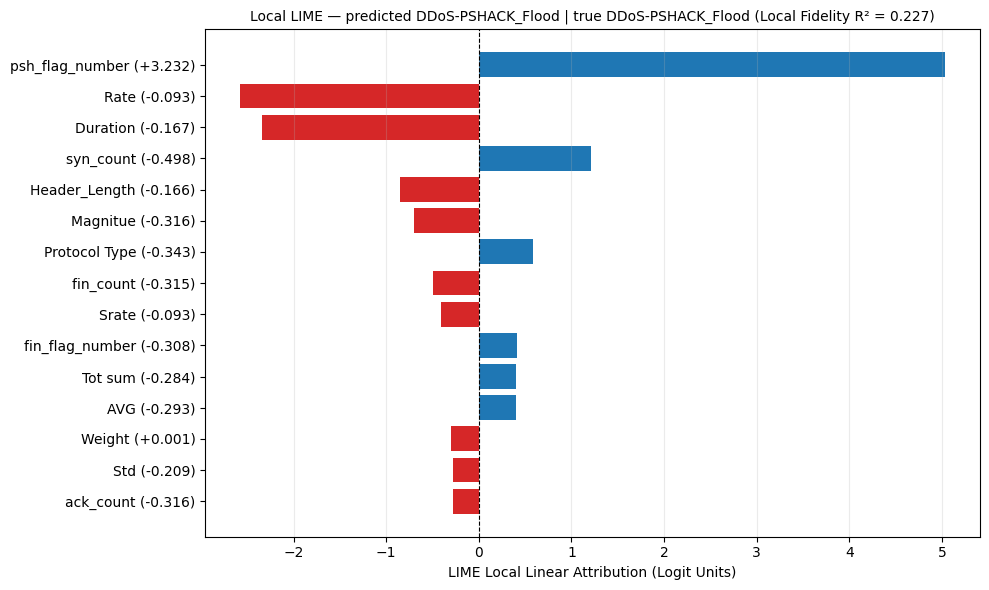

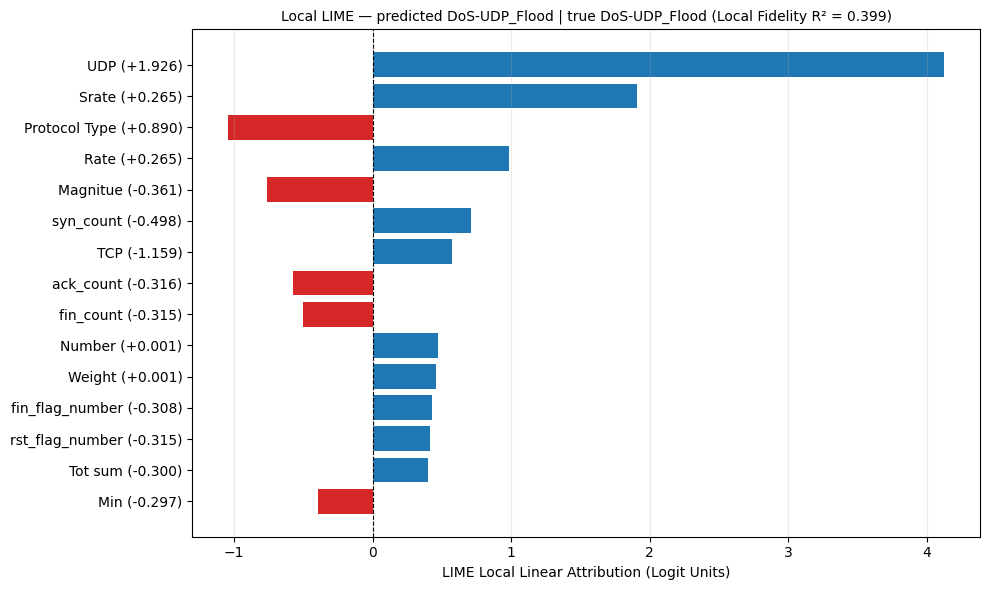

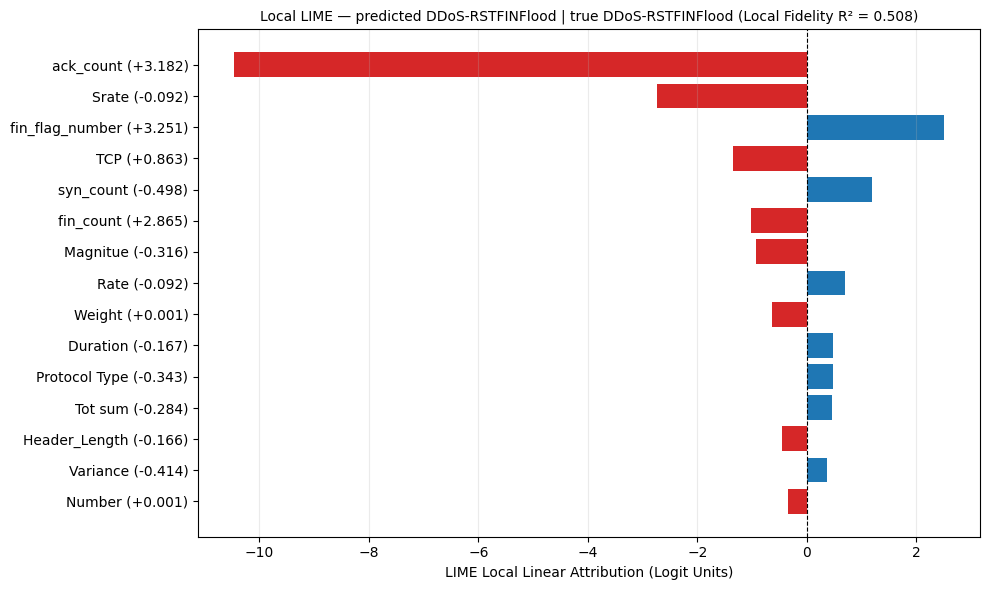

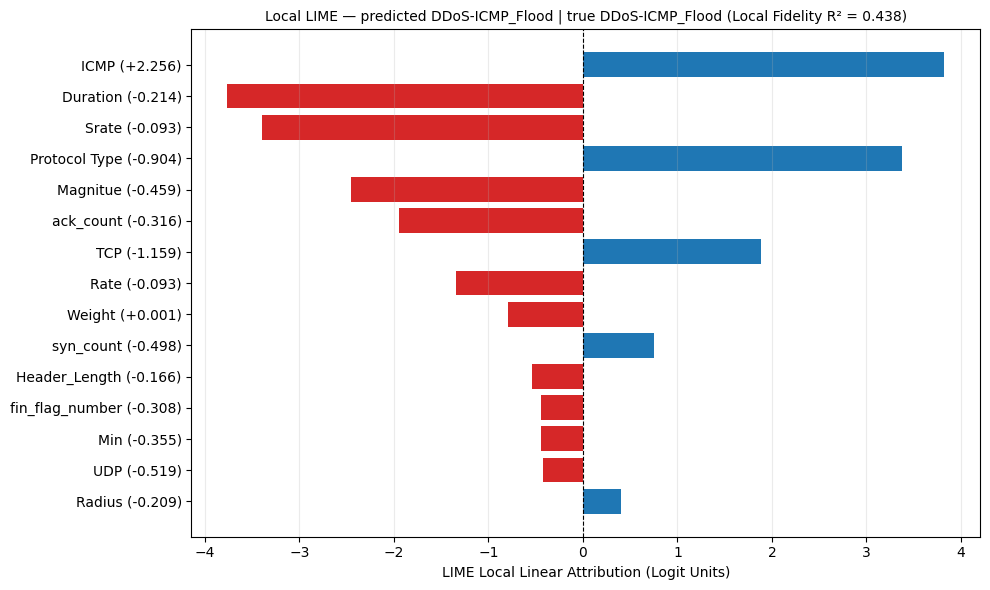

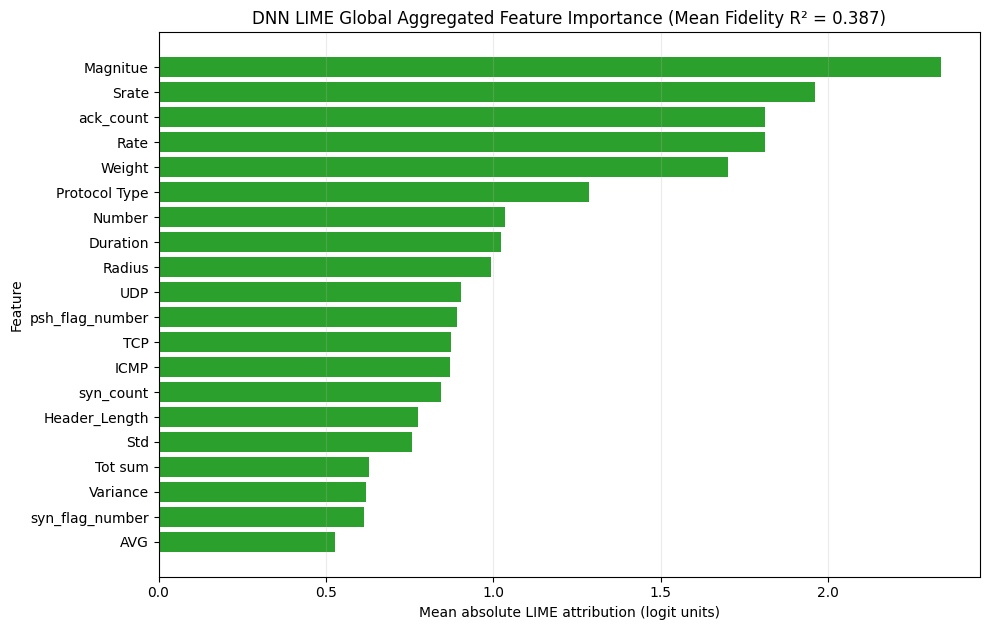

Mean LIME Local Fidelity R²: 0.3866
SHAP vs. LIME Global Feature Ranking Spearman rho: 0.6710
Mean Per-Sample Top-5 Feature Overlap: 0.438
Mean Per-Sample Top-10 Feature Overlap: 0.519


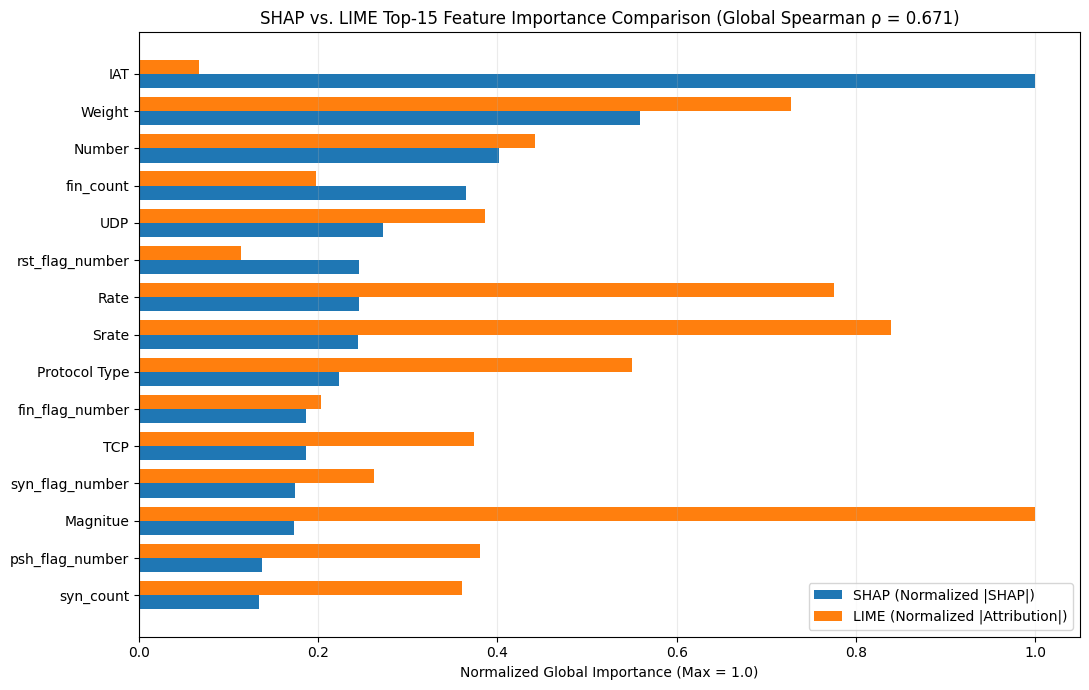

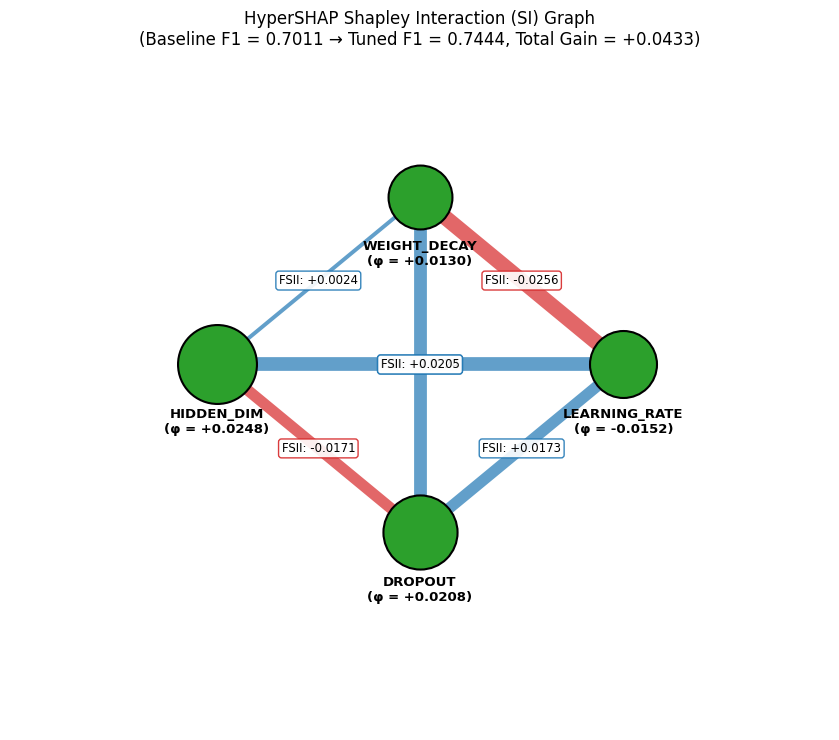


========== [XAI 3/3] RUNNING HYPERSHAP (HPO EXPLAINABILITY) ==========
Evaluating 16 exact ablation coalitions + 24 random HPO configurations...

HyperSHAP Main Effects Table:
hyperparameter  baseline_value  tuned_optimal_value  ablation_shapley  tunability_shapley  sensitivity_shapley  ablation_abs_share
    HIDDEN_DIM           64.00           208.000000          0.024811            0.005248             0.001731            0.336496
       DROPOUT            0.45             0.031400          0.020761            0.010002             0.003553            0.281569
 LEARNING_RATE            0.01             0.000693         -0.015196            0.018179             0.031622            0.206090
  WEIGHT_DECAY            0.01             0.000011          0.012966           -0.000308             0.006918            0.175845


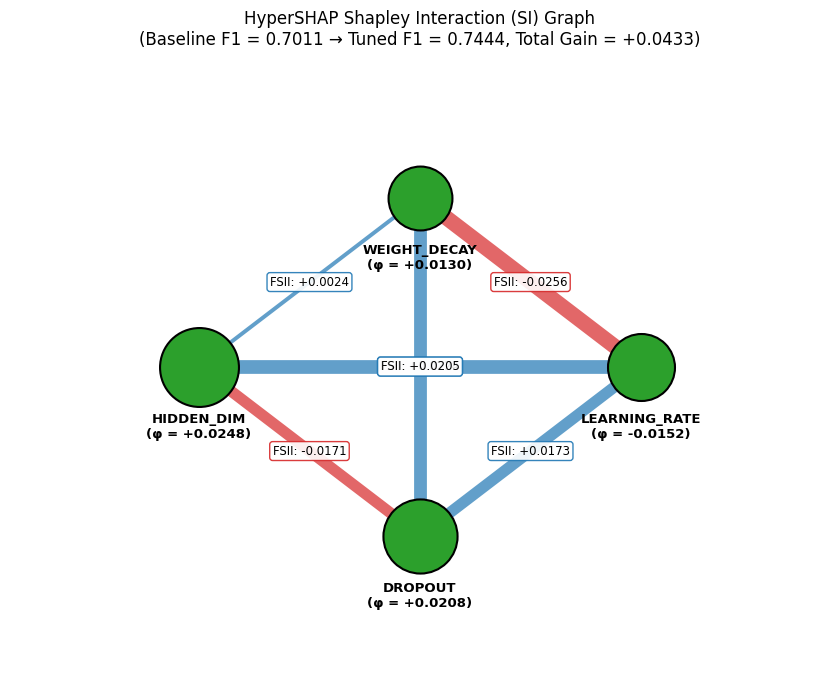

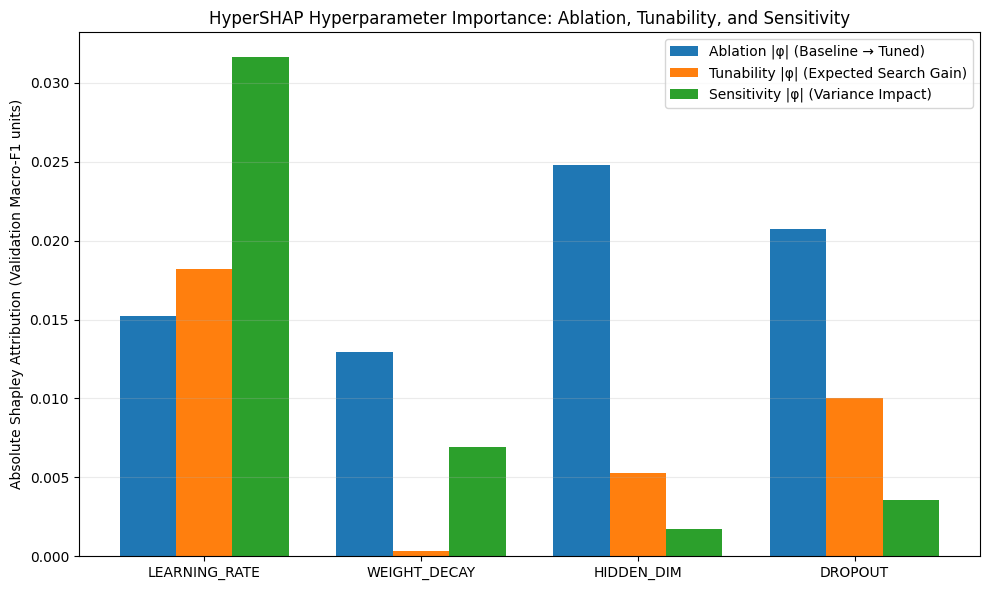

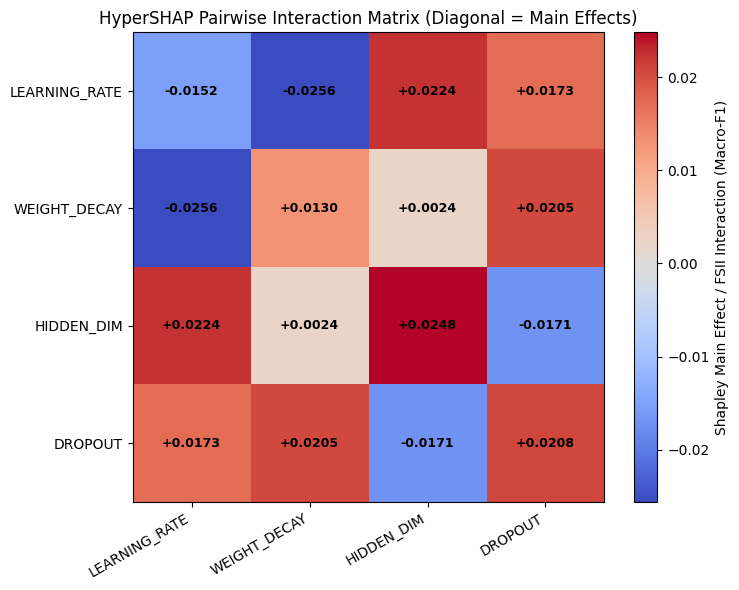

In [5]:
# ============================================================
# CICIoT2023 — Sampled DNN Intrusion Detection Pipeline
# Full Thesis Pipeline + 3-Pillar XAI (SHAP + LIME + HyperSHAP)
# ============================================================

import os
import sys
import json
import copy
import random
import subprocess
import warnings
from itertools import combinations
from math import factorial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve, average_precision_score
)
from sklearn.calibration import calibration_curve

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import joblib

warnings.filterwarnings("ignore")

# ============================================================
# 0. AUTO-INSTALL XAI DEPENDENCIES (KAGGLE COMPATIBLE)
# ============================================================

def ensure_package(import_name, pip_name=None):
    pip_pkg = pip_name or import_name
    try:
        __import__(import_name)
    except ImportError:
        print(f"Installing {pip_pkg}...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", pip_pkg]
        )

ensure_package("shap")
ensure_package("lime")
ensure_package("ConfigSpace")
try:
    ensure_package("hypershap")
except Exception as e:
    print(f"Note: hypershap pip installation skipped/fell back ({e}). Exact FSII solver ready.")

import shap
from lime.lime_tabular import LimeTabularExplainer

# ============================================================
# 1. CONFIGURATION — ORIGINAL PARAMETERS PRESERVED
# ============================================================

TRAIN_PATH = "/kaggle/input/datasets/himadri07/ciciot2023/CICIOT23/train/train.csv"
VAL_PATH   = "/kaggle/input/datasets/himadri07/ciciot2023/CICIOT23/validation/validation.csv"
TEST_PATH  = "/kaggle/input/datasets/himadri07/ciciot2023/CICIOT23/test/test.csv"

TRAIN_ROWS = 580_000
VAL_ROWS   = 60_000
TEST_ROWS  = 60_000

SAMPLE_MODE = "first"
RANDOM_SEED = 42
CHUNK_SIZE = 100_000

TARGET_COL = "label"
CLASS_THRESHOLD = 15_000
MAX_MISSING_RATIO = 0.50
DROP_DUPLICATES_WITHIN_SPLIT = True
DROP_IDENTIFIER_COLUMNS = True

BATCH_SIZE = 2048
EPOCHS = 50
PATIENCE = 5
MIN_DELTA = 1e-4
LEARNING_RATE = 0.0006934643108701212
WEIGHT_DECAY = 1.0849999715758006e-05
HIDDEN_DIM = 208
DROPOUT = 0.0314
NUM_WORKERS = 0

OUTPUT_DIR = "/kaggle/working/ciciot_dnn_sample_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 2. REPRODUCIBILITY AND DEVICE
# ============================================================

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 3. LOAD CONFIGURABLE SAMPLES — ORIGINAL LOADER
# ============================================================

def load_csv_sample(path, nrows, mode="first", seed=42, chunksize=100_000):
    if not os.path.isfile(path):
        raise FileNotFoundError(f"CSV file not found: {path}")

    if nrows is not None and nrows <= 0:
        raise ValueError("Sample row limits must be positive integers.")

    print(f"\nLoading {path}")
    print(f"Sampling mode={mode}, requested rows={nrows:,}")

    if mode == "first":
        df = pd.read_csv(path, nrows=nrows, low_memory=False)

    elif mode == "random":
        reservoir = []
        columns = None
        seen = 0
        rng = np.random.default_rng(seed)

        for chunk in pd.read_csv(path, chunksize=chunksize, low_memory=False):
            if columns is None:
                columns = chunk.columns.tolist()

            for row in chunk.itertuples(index=False, name=None):
                seen += 1
                if len(reservoir) < nrows:
                    reservoir.append(row)
                else:
                    j = int(rng.integers(0, seen))
                    if j < nrows:
                        reservoir[j] = row

        df = pd.DataFrame(reservoir, columns=columns)

    else:
        raise ValueError("SAMPLE_MODE must be 'first' or 'random'.")

    if df.empty:
        raise ValueError(f"No data loaded from {path}")

    df.columns = df.columns.astype(str).str.strip()
    print("Loaded:", df.shape)
    return df


train_df = load_csv_sample(TRAIN_PATH, TRAIN_ROWS, SAMPLE_MODE, RANDOM_SEED, CHUNK_SIZE)
val_df   = load_csv_sample(VAL_PATH, VAL_ROWS, SAMPLE_MODE, RANDOM_SEED + 1, CHUNK_SIZE)
test_df  = load_csv_sample(TEST_PATH, TEST_ROWS, SAMPLE_MODE, RANDOM_SEED + 2, CHUNK_SIZE)

# ============================================================
# 4. FIND LABEL COLUMN AND ALIGN SCHEMAS
# ============================================================

def find_target_column(df, preferred="label"):
    if preferred in df.columns:
        return preferred

    candidates = ["label", "Label", "target", "Target", "class", "Class", "attack", "Attack"]
    for col in candidates:
        if col in df.columns:
            return col

    raise ValueError(
        "Target/label column not found. Available columns:\n"
        + ", ".join(df.columns.tolist())
    )


TARGET_COL = find_target_column(train_df, TARGET_COL)
print("\nTarget column:", TARGET_COL)

for split_name, df in [("validation", val_df), ("test", test_df)]:
    if TARGET_COL not in df.columns:
        raise ValueError(f"{split_name} CSV does not contain target column '{TARGET_COL}'.")

train_columns = train_df.columns.tolist()

for split_name, df in [("validation", val_df), ("test", test_df)]:
    missing = sorted(set(train_columns) - set(df.columns))
    if missing:
        raise ValueError(f"{split_name} is missing columns from train CSV: {missing}")

train_df = train_df[train_columns].copy()
val_df   = val_df[train_columns].copy()
test_df  = test_df[train_columns].copy()

# ============================================================
# 5. CLEAN INVALID RECORDS AND WITHIN-SPLIT DUPLICATES
# ============================================================

def clean_split(df, split_name):
    df = df.copy()
    rows_before = len(df)

    df[TARGET_COL] = df[TARGET_COL].astype("string").str.strip()
    df[TARGET_COL] = df[TARGET_COL].replace("", pd.NA)
    df = df.dropna(subset=[TARGET_COL])

    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if numeric_cols:
        df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)

    duplicate_count = 0
    if DROP_DUPLICATES_WITHIN_SPLIT:
        before_dedup = len(df)
        df = df.drop_duplicates()
        duplicate_count = before_dedup - len(df)

    print(
        f"{split_name}: {rows_before:,} -> {len(df):,} rows; "
        f"duplicates removed={duplicate_count:,}; "
        f"missing labels removed={rows_before - len(df) - duplicate_count:,}"
    )

    return df.reset_index(drop=True)


train_df = clean_split(train_df, "TRAIN")
val_df   = clean_split(val_df, "VALIDATION")
test_df  = clean_split(test_df, "TEST")

# ============================================================
# 6. FEATURES AND TRAIN-ONLY FEATURE SELECTION
# ============================================================

y_train_raw = train_df[TARGET_COL].astype(str).str.strip()
y_val_raw   = val_df[TARGET_COL].astype(str).str.strip()
y_test_raw  = test_df[TARGET_COL].astype(str).str.strip()

X_train_df = train_df.drop(columns=[TARGET_COL]).copy()
X_val_df   = val_df.drop(columns=[TARGET_COL]).copy()
X_test_df  = test_df.drop(columns=[TARGET_COL]).copy()

all_missing_cols = X_train_df.columns[X_train_df.isna().all()].tolist()

missing_ratio = X_train_df.isna().mean()
high_missing_cols = missing_ratio[missing_ratio > MAX_MISSING_RATIO].index.tolist()

identifier_tokens = [
    "flow_id", "src_ip", "dst_ip", "source_ip", "destination_ip",
    "timestamp", "mac_address", "source_mac", "destination_mac"
]

identifier_cols = []
if DROP_IDENTIFIER_COLUMNS:
    for col in X_train_df.columns:
        normalized = str(col).lower().replace(" ", "_").replace("-", "_")
        if any(token in normalized for token in identifier_tokens):
            identifier_cols.append(col)

non_numeric_cols = X_train_df.select_dtypes(exclude=[np.number]).columns.tolist()

drop_cols = sorted(set(
    all_missing_cols + high_missing_cols + identifier_cols + non_numeric_cols
))

print("\nFeature columns removed:")
print(drop_cols if drop_cols else "None")

X_train_df.drop(columns=drop_cols, inplace=True, errors="ignore")
X_val_df.drop(columns=drop_cols, inplace=True, errors="ignore")
X_test_df.drop(columns=drop_cols, inplace=True, errors="ignore")

X_val_df  = X_val_df[X_train_df.columns]
X_test_df = X_test_df[X_train_df.columns]

constant_cols = [
    c for c in X_train_df.columns if X_train_df[c].nunique(dropna=True) <= 1
]

if constant_cols:
    print("Constant feature columns removed:", constant_cols)
    X_train_df.drop(columns=constant_cols, inplace=True)
    X_val_df.drop(columns=constant_cols, inplace=True)
    X_test_df.drop(columns=constant_cols, inplace=True)

if X_train_df.shape[1] == 0:
    raise ValueError("No usable numeric features remain after preprocessing.")

# ============================================================
# 7. RARE-LABEL HANDLING — ORIGINAL BEHAVIOR
# ============================================================

train_label_counts = y_train_raw.value_counts()
kept_labels = set(train_label_counts[train_label_counts >= CLASS_THRESHOLD].index)

def group_rare_labels(labels):
    return labels.where(labels.isin(kept_labels), "Others")

y_train_grouped = group_rare_labels(y_train_raw)
y_val_grouped   = group_rare_labels(y_val_raw)
y_test_grouped  = group_rare_labels(y_test_raw)

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_grouped)
class_names = label_encoder.classes_.tolist()
label_to_id = {label: idx for idx, label in enumerate(class_names)}

unseen_val  = sorted(set(y_val_grouped) - set(label_to_id))
unseen_test = sorted(set(y_test_grouped) - set(label_to_id))

if unseen_val or unseen_test:
    if "Others" not in label_to_id:
        print("\nWARNING: Evaluation contains unseen labels.")
        print("Validation unseen labels:", unseen_val)
        print("Test unseen labels:", unseen_test)

def encode_evaluation_labels(labels):
    encoded = np.full(len(labels), -1, dtype=np.int64)
    for i, label in enumerate(labels):
        if label in label_to_id:
            encoded[i] = label_to_id[label]
        elif "Others" in label_to_id:
            encoded[i] = label_to_id["Others"]
    return encoded

y_val  = encode_evaluation_labels(y_val_grouped)
y_test = encode_evaluation_labels(y_test_grouped)

print("\nTraining class counts after rare-label grouping:")
print(
    pd.Series(y_train).value_counts().sort_index().rename(
        index=dict(enumerate(class_names))
    )
)
print("Classes:", len(class_names))
print("Features:", X_train_df.shape[1])

# ============================================================
# 8. IMPUTE AND SCALE — FIT ON TRAIN ONLY
# ============================================================

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train_df)
X_val   = imputer.transform(X_val_df)
X_test  = imputer.transform(X_test_df)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

X_train = np.asarray(X_train, dtype=np.float32)
X_val   = np.asarray(X_val, dtype=np.float32)
X_test  = np.asarray(X_test, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.int64)

print("\n========== FINAL DATA SHAPES ==========")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print(
    "NaN in features:",
    np.isnan(X_train).any(), np.isnan(X_val).any(), np.isnan(X_test).any()
)
print(
    "Inf in features:",
    np.isinf(X_train).any(), np.isinf(X_val).any(), np.isinf(X_test).any()
)

preprocessing_summary = {
    "target_column": TARGET_COL,
    "sample_mode": SAMPLE_MODE,
    "requested_rows": {"train": TRAIN_ROWS, "validation": VAL_ROWS, "test": TEST_ROWS},
    "actual_rows": {"train": len(X_train), "validation": len(X_val), "test": len(X_test)},
    "feature_count": int(X_train.shape[1]),
    "feature_columns": X_train_df.columns.tolist(),
    "dropped_columns": drop_cols + constant_cols,
    "class_names": class_names,
    "class_threshold": CLASS_THRESHOLD
}

pd.Series({k: str(v) for k, v in preprocessing_summary.items()}).to_json(
    os.path.join(OUTPUT_DIR, "preprocessing_summary.json"), indent=2
)

# ============================================================
# 9. CLASS DISTRIBUTION PLOT
# ============================================================

def save_graph(filename):
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

fig, ax = plt.subplots(figsize=(12, 5))
pd.Series(y_train).value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Training Sample Class Distribution (Encoded Labels)")
ax.set_xlabel("Encoded class")
ax.set_ylabel("Rows")
save_graph("01_class_distribution.png")

# ============================================================
# 10. PYTORCH DATA LOADERS
# ============================================================

def make_loader(X, y, batch_size, shuffle=False):
    valid = y >= 0
    X = X[valid]
    y = y[valid]

    dataset = TensorDataset(
        torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32)),
        torch.from_numpy(np.ascontiguousarray(y, dtype=np.int64))
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )

train_loader = make_loader(X_train, y_train, BATCH_SIZE, shuffle=True)
val_loader   = make_loader(X_val, y_val, BATCH_SIZE, shuffle=False)
test_loader  = make_loader(X_test, y_test, BATCH_SIZE, shuffle=False)

if len(train_loader.dataset) == 0:
    raise ValueError("No training rows available.")
if len(val_loader.dataset) == 0:
    raise ValueError("No validation rows available after label handling.")

# ============================================================
# 11. DNN MODEL — ORIGINAL ARCHITECTURE
# ============================================================

class IntrusionDNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, dropout):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.network(x)


num_classes = len(class_names)

model = IntrusionDNN(
    input_dim=X_train.shape[1],
    hidden_dim=HIDDEN_DIM,
    num_classes=num_classes,
    dropout=DROPOUT
).to(device)

counts = np.bincount(y_train, minlength=num_classes).astype(np.float64)
class_weights = counts.sum() / np.maximum(counts, 1)
class_weights = class_weights / class_weights.mean()

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

print(
    "\nModel parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)
print("Class names:", class_names)

# ============================================================
# 12. TRAINING / VALIDATION HELPERS
# ============================================================

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_n = 0
    all_true, all_pred = [], []

    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = criterion(logits, yb)

            if training:
                loss.backward()
                optimizer.step()

        batch_n = len(yb)
        total_loss += loss.item() * batch_n
        total_n += batch_n

        preds = torch.argmax(logits, dim=1)
        all_true.append(yb.detach().cpu().numpy())
        all_pred.append(preds.detach().cpu().numpy())

    if total_n == 0:
        return {
            "loss": np.nan, "accuracy": np.nan, "macro_f1": np.nan,
            "macro_precision": np.nan, "macro_recall": np.nan
        }

    y_true = np.concatenate(all_true)
    y_pred = np.concatenate(all_pred)

    return {
        "loss": total_loss / total_n,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0)
    }


history = {
    "train_loss": [], "val_loss": [],
    "train_accuracy": [], "val_accuracy": [],
    "train_macro_f1": [], "val_macro_f1": [],
    "train_precision": [], "val_precision": [],
    "train_recall": [], "val_recall": []
}

best_val_f1 = -1.0
best_epoch = 0
best_state = None
epochs_without_improvement = 0

# ============================================================
# 13. TRAIN — ORIGINAL EARLY-STOPPING LOGIC
# ============================================================

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, criterion, optimizer)
    val_metrics   = run_epoch(model, val_loader, criterion, optimizer=None)

    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["train_macro_f1"].append(train_metrics["macro_f1"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["train_precision"].append(train_metrics["macro_precision"])
    history["val_precision"].append(val_metrics["macro_precision"])
    history["train_recall"].append(train_metrics["macro_recall"])
    history["val_recall"].append(val_metrics["macro_recall"])

    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"Train loss={train_metrics['loss']:.5f}, "
        f"acc={train_metrics['accuracy']:.5f}, "
        f"macro-F1={train_metrics['macro_f1']:.5f} | "
        f"Val loss={val_metrics['loss']:.5f}, "
        f"acc={val_metrics['accuracy']:.5f}, "
        f"macro-F1={val_metrics['macro_f1']:.5f}"
    )

    if val_metrics["macro_f1"] > best_val_f1 + MIN_DELTA:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
        torch.save(best_state, os.path.join(OUTPUT_DIR, "best_dnn_model.pt"))
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}. Best epoch: {best_epoch}")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a best model checkpoint.")

model.load_state_dict(best_state)
print(
    f"\nRestored best checkpoint from epoch {best_epoch}, "
    f"val macro-F1={best_val_f1:.6f}"
)

pd.DataFrame(history).to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"), index=False
)

# ============================================================
# 14. LEARNING CURVES — ORIGINAL + ADDITIONAL GRAPHS
# ============================================================

def plot_history(train_key, val_key, title, ylabel, filename):
    plt.figure(figsize=(9, 5))
    plt.plot(history[train_key], label="Train")
    plt.plot(history[val_key], label="Validation")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(alpha=0.25)
    save_graph(filename)

plot_history("train_loss", "val_loss", "Training vs Validation Loss", "Loss", "02_loss.png")
plot_history("train_accuracy", "val_accuracy", "Training vs Validation Accuracy", "Accuracy", "03_accuracy.png")
plot_history("train_macro_f1", "val_macro_f1", "Training vs Validation Macro-F1", "Macro-F1", "04_macro_f1.png")
plot_history("train_precision", "val_precision", "Training vs Validation Macro Precision", "Macro Precision", "05_precision.png")
plot_history("train_recall", "val_recall", "Training vs Validation Macro Recall", "Macro Recall", "06_recall.png")

epochs_axis   = np.arange(1, len(history["train_loss"]) + 1)
loss_gap      = np.asarray(history["val_loss"]) - np.asarray(history["train_loss"])
accuracy_gap  = np.asarray(history["train_accuracy"]) - np.asarray(history["val_accuracy"])
f1_gap        = np.asarray(history["train_macro_f1"]) - np.asarray(history["val_macro_f1"])
precision_gap = np.asarray(history["train_precision"]) - np.asarray(history["val_precision"])
recall_gap    = np.asarray(history["train_recall"]) - np.asarray(history["val_recall"])

plt.figure(figsize=(9, 5))
plt.plot(epochs_axis, loss_gap, label="Validation - Train loss")
plt.axhline(0, linestyle="--")
plt.title("Generalization Gap — Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation loss - training loss")
plt.legend()
plt.grid(alpha=0.25)
save_graph("07_generalization_gap_loss.png")

plt.figure(figsize=(9, 5))
plt.plot(epochs_axis, accuracy_gap, label="Train - Validation accuracy")
plt.axhline(0, linestyle="--")
plt.title("Generalization Gap — Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Training accuracy - validation accuracy")
plt.legend()
plt.grid(alpha=0.25)
save_graph("08_generalization_gap_accuracy.png")

plt.figure(figsize=(9, 5))
plt.plot(epochs_axis, f1_gap, label="Train - Validation macro-F1")
plt.axhline(0, linestyle="--")
plt.title("Generalization Gap — Macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Training macro-F1 - validation macro-F1")
plt.legend()
plt.grid(alpha=0.25)
save_graph("09_generalization_gap_f1.png")

plt.figure(figsize=(10, 6))
plt.plot(epochs_axis, accuracy_gap, label="Accuracy gap")
plt.plot(epochs_axis, f1_gap, label="Macro-F1 gap")
plt.plot(epochs_axis, precision_gap, label="Precision gap")
plt.plot(epochs_axis, recall_gap, label="Recall gap")
plt.axhline(0, linestyle="--")
plt.title("Generalization Gaps Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Training - validation difference")
plt.legend()
plt.grid(alpha=0.25)
save_graph("10_generalization_gaps_combined.png")

# ============================================================
# 15. TEST EVALUATION — ORIGINAL PROCEDURE
# ============================================================

def predict_loader(model, loader):
    model.eval()
    true_list, pred_list, prob_list = [], [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True)
            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            true_list.append(yb.numpy())
            pred_list.append(preds.cpu().numpy())
            prob_list.append(probs.cpu().numpy())

    if not true_list:
        return np.array([]), np.array([]), np.empty((0, num_classes))

    return (
        np.concatenate(true_list),
        np.concatenate(pred_list),
        np.concatenate(prob_list)
    )

y_true_test, y_pred_test, y_prob_test = predict_loader(model, test_loader)

if len(y_true_test) == 0:
    print("\nWARNING: No test rows had labels represented in training.")
else:
    metrics = {
        "test_accuracy": accuracy_score(y_true_test, y_pred_test),
        "test_macro_precision": precision_score(y_true_test, y_pred_test, average="macro", zero_division=0),
        "test_macro_recall": recall_score(y_true_test, y_pred_test, average="macro", zero_division=0),
        "test_macro_f1": f1_score(y_true_test, y_pred_test, average="macro", zero_division=0),
        "test_weighted_f1": f1_score(y_true_test, y_pred_test, average="weighted", zero_division=0)
    }

    print("\n========== TEST RESULTS ==========")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.6f}")

    present_labels = np.unique(np.concatenate([y_true_test, y_pred_test]))

    report = classification_report(
        y_true_test, y_pred_test,
        labels=present_labels,
        target_names=[class_names[i] for i in present_labels],
        zero_division=0,
        digits=5
    )

    print("\nClassification Report:\n", report)

    with open(os.path.join(OUTPUT_DIR, "test_classification_report.txt"), "w") as f:
        f.write(report)

    pd.Series(metrics).to_json(os.path.join(OUTPUT_DIR, "test_metrics.json"), indent=2)

    # A. CONFUSION MATRIX — COUNTS
    cm = confusion_matrix(y_true_test, y_pred_test, labels=present_labels)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[class_names[i] for i in present_labels]
    )
    fig, ax = plt.subplots(
        figsize=(max(8, len(present_labels) * 0.8), max(6, len(present_labels) * 0.65))
    )
    disp.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
    ax.set_title("Test Confusion Matrix — Counts")
    save_graph("11_test_confusion_matrix.png")

    # B. NORMALIZED CONFUSION MATRIX
    cm_normalized = confusion_matrix(
        y_true_test, y_pred_test, labels=present_labels, normalize="true"
    )
    fig, ax = plt.subplots(
        figsize=(max(8, len(present_labels) * 0.8), max(6, len(present_labels) * 0.65))
    )
    im = ax.imshow(cm_normalized, cmap="Blues", aspect="auto")
    fig.colorbar(im, ax=ax)
    ax.set_title("Normalized Test Confusion Matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(np.arange(len(present_labels)))
    ax.set_yticks(np.arange(len(present_labels)))
    ax.set_xticklabels([class_names[i] for i in present_labels], rotation=90, fontsize=7)
    ax.set_yticklabels([class_names[i] for i in present_labels], fontsize=7)

    if len(present_labels) <= 20:
        for i in range(len(present_labels)):
            for j in range(len(present_labels)):
                ax.text(j, i, f"{cm_normalized[i, j]:.2f}", ha="center", va="center", fontsize=6)

    save_graph("12_normalized_confusion_matrix.png")

    # C. PER-CLASS PRECISION / RECALL / F1
    report_dict = classification_report(
        y_true_test, y_pred_test,
        labels=np.arange(num_classes),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    per_class_df = pd.DataFrame(report_dict).T
    per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"))

    per_class_scores = per_class_df.reindex(class_names)[["precision", "recall", "f1-score"]]
    x = np.arange(num_classes)
    width = 0.25

    plt.figure(figsize=(max(10, num_classes * 0.8), 6))
    plt.bar(x - width, per_class_scores["precision"], width, label="Precision")
    plt.bar(x, per_class_scores["recall"], width, label="Recall")
    plt.bar(x + width, per_class_scores["f1-score"], width, label="F1-score")
    plt.xticks(x, class_names, rotation=90)
    plt.ylim(0, 1.05)
    plt.title("Per-Class Test Precision, Recall and F1")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(axis="y", alpha=0.25)
    save_graph("13_per_class_metrics.png")

    # D. ROC CURVES — MULTICLASS ONE-VS-REST
    class_ids = np.arange(num_classes)
    y_test_binary = label_binarize(y_true_test, classes=class_ids)
    if num_classes == 2 and y_test_binary.shape[1] == 1:
        y_test_binary = np.column_stack([1 - y_test_binary[:, 0], y_test_binary[:, 0]])

    roc_auc_by_class = {}
    plt.figure(figsize=(10, 8))
    for i, class_name in enumerate(class_names):
        binary_true = y_test_binary[:, i]
        if len(np.unique(binary_true)) < 2:
            continue
        fpr, tpr, _ = roc_curve(binary_true, y_prob_test[:, i])
        class_auc = auc(fpr, tpr)
        roc_auc_by_class[class_name] = float(class_auc)
        plt.plot(fpr, tpr, label=f"{class_name} (AUC={class_auc:.3f})")

    plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Multiclass ROC Curves — One-vs-Rest")
    plt.legend(loc="lower right", fontsize=7)
    plt.grid(alpha=0.25)
    save_graph("14_multiclass_roc.png")

    pd.Series(roc_auc_by_class, name="ROC_AUC").to_csv(
        os.path.join(OUTPUT_DIR, "per_class_roc_auc.csv")
    )

    # E. MICRO-AVERAGE ROC
    if y_test_binary.shape == y_prob_test.shape:
        fpr_micro, tpr_micro, _ = roc_curve(y_test_binary.ravel(), y_prob_test.ravel())
        micro_auc = auc(fpr_micro, tpr_micro)
        plt.figure(figsize=(8, 6))
        plt.plot(fpr_micro, tpr_micro, label=f"Micro-average ROC-AUC = {micro_auc:.4f}")
        plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("Micro-Average ROC Curve")
        plt.legend()
        plt.grid(alpha=0.25)
        save_graph("15_micro_average_roc.png")
        print(f"Micro-average ROC-AUC: {micro_auc:.6f}")

    # F. PRECISION-RECALL CURVES
    average_precision_by_class = {}
    plt.figure(figsize=(10, 8))
    for i, class_name in enumerate(class_names):
        binary_true = y_test_binary[:, i]
        if binary_true.sum() == 0:
            continue
        precision_curve, recall_curve, _ = precision_recall_curve(
            binary_true, y_prob_test[:, i]
        )
        ap = average_precision_score(binary_true, y_prob_test[:, i])
        average_precision_by_class[class_name] = float(ap)
        plt.plot(recall_curve, precision_curve, label=f"{class_name} (AP={ap:.3f})")

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Multiclass Precision-Recall Curves")
    plt.legend(loc="best", fontsize=7)
    plt.grid(alpha=0.25)
    save_graph("16_precision_recall_curves.png")

    pd.Series(average_precision_by_class, name="Average_Precision").to_csv(
        os.path.join(OUTPUT_DIR, "per_class_average_precision.csv")
    )

    # G. MULTICLASS LIFT CHART
    binary_flat = y_test_binary.ravel()
    scores_flat = y_prob_test.ravel()
    ranking = np.argsort(scores_flat)[::-1]
    truth_ranked = binary_flat[ranking]
    total_pairs = len(truth_ranked)
    total_positives = truth_ranked.sum()

    if total_positives > 0:
        cumulative_positives = np.cumsum(truth_ranked)
        fraction_selected = np.arange(1, total_pairs + 1) / total_pairs
        cumulative_gain = cumulative_positives / total_positives
        lift_values = cumulative_gain / fraction_selected
        plot_idx = np.unique(
            np.linspace(0, total_pairs - 1, min(2000, total_pairs)).astype(int)
        )

        plt.figure(figsize=(9, 6))
        plt.plot(fraction_selected[plot_idx] * 100, lift_values[plot_idx], label="DNN lift")
        plt.axhline(1.0, linestyle="--", label="Random baseline (lift = 1)")
        plt.xlabel("Top-ranked sample-class pairs selected (%)")
        plt.ylabel("Cumulative lift")
        plt.title("Multiclass Micro-Average Lift Chart")
        plt.legend()
        plt.grid(alpha=0.25)
        save_graph("17_lift_chart.png")

    # H. CONFIDENCE CALIBRATION
    confidence = y_prob_test.max(axis=1)
    correct_prediction = (y_pred_test == y_true_test).astype(int)

    if len(np.unique(correct_prediction)) > 1:
        observed_accuracy, mean_confidence = calibration_curve(
            correct_prediction, confidence, n_bins=10, strategy="uniform"
        )
        plt.figure(figsize=(8, 6))
        plt.plot(mean_confidence, observed_accuracy, marker="o", label="DNN")
        plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
        plt.xlabel("Mean predicted confidence")
        plt.ylabel("Observed accuracy")
        plt.title("Prediction Confidence Calibration")
        plt.legend()
        plt.grid(alpha=0.25)
        save_graph("18_confidence_calibration.png")

    # I. CORRECT VS INCORRECT PREDICTION CONFIDENCE
    correct_mask = y_pred_test == y_true_test
    plt.figure(figsize=(9, 6))
    plt.hist(confidence[correct_mask], bins=25, alpha=0.65, label="Correct predictions")
    plt.hist(confidence[~correct_mask], bins=25, alpha=0.65, label="Incorrect predictions")
    plt.xlabel("Maximum predicted probability")
    plt.ylabel("Number of predictions")
    plt.title("Confidence Distribution: Correct vs Incorrect")
    plt.legend()
    plt.grid(alpha=0.25)
    save_graph("19_prediction_confidence.png")

    # J. MACRO VS WEIGHTED TEST METRICS
    metric_names = ["Precision", "Recall", "F1-score"]
    macro_values = [
        precision_score(y_true_test, y_pred_test, average="macro", zero_division=0),
        recall_score(y_true_test, y_pred_test, average="macro", zero_division=0),
        f1_score(y_true_test, y_pred_test, average="macro", zero_division=0)
    ]
    weighted_values = [
        precision_score(y_true_test, y_pred_test, average="weighted", zero_division=0),
        recall_score(y_true_test, y_pred_test, average="weighted", zero_division=0),
        f1_score(y_true_test, y_pred_test, average="weighted", zero_division=0)
    ]
    x = np.arange(len(metric_names))
    width = 0.35

    plt.figure(figsize=(8, 6))
    plt.bar(x - width / 2, macro_values, width, label="Macro")
    plt.bar(x + width / 2, weighted_values, width, label="Weighted")
    plt.xticks(x, metric_names)
    plt.ylim(0, 1.05)
    plt.ylabel("Score")
    plt.title("Macro vs Weighted Test Metrics")
    plt.legend()
    plt.grid(axis="y", alpha=0.25)
    save_graph("20_macro_vs_weighted_metrics.png")

    # K. TEST CLASS DISTRIBUTION
    support = pd.Series(y_true_test).value_counts().reindex(class_ids, fill_value=0)
    plt.figure(figsize=(max(10, num_classes * 0.8), 6))
    plt.bar(class_names, support.values)
    plt.title("Test Set Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Number of samples")
    plt.xticks(rotation=90)
    plt.grid(axis="y", alpha=0.25)
    save_graph("21_test_class_distribution.png")

    # L. SAVE TEST PREDICTIONS
    prediction_df = pd.DataFrame({
        "true_encoded": y_true_test,
        "true_label": [class_names[i] for i in y_true_test],
        "pred_encoded": y_pred_test,
        "pred_label": [class_names[i] for i in y_pred_test],
        "confidence": y_prob_test.max(axis=1)
    })
    prediction_df.to_csv(os.path.join(OUTPUT_DIR, "test_predictions.csv"), index=False)

# ============================================================
# 16. SAVE MODEL AND PREPROCESSORS — ORIGINAL BEHAVIOR
# ============================================================

torch.save({
    "model_state_dict": model.state_dict(),
    "input_dim": int(X_train.shape[1]),
    "hidden_dim": HIDDEN_DIM,
    "num_classes": num_classes,
    "dropout": DROPOUT,
    "class_names": class_names,
    "feature_columns": X_train_df.columns.tolist(),
    "best_epoch": best_epoch,
    "best_val_macro_f1": best_val_f1,
    "config": {
        "TRAIN_ROWS": TRAIN_ROWS,
        "VAL_ROWS": VAL_ROWS,
        "TEST_ROWS": TEST_ROWS,
        "SAMPLE_MODE": SAMPLE_MODE,
        "CLASS_THRESHOLD": CLASS_THRESHOLD,
        "BATCH_SIZE": BATCH_SIZE,
        "EPOCHS": EPOCHS,
        "LEARNING_RATE": LEARNING_RATE,
        "WEIGHT_DECAY": WEIGHT_DECAY,
        "HIDDEN_DIM": HIDDEN_DIM,
        "DROPOUT": DROPOUT
    }
}, os.path.join(OUTPUT_DIR, "final_dnn_checkpoint.pt"))

joblib.dump(imputer, os.path.join(OUTPUT_DIR, "imputer.joblib"))
joblib.dump(scaler, os.path.join(OUTPUT_DIR, "scaler.joblib"))
joblib.dump(label_encoder, os.path.join(OUTPUT_DIR, "label_encoder.joblib"))



# ============================================================
# 17. PILLAR 1: SHAP EXPLAINABLE AI (XAI) — FIXED & POLISHED
# ============================================================

SHAP_BACKGROUND_SIZE = 100
SHAP_EXPLAIN_SIZE = 200
SHAP_RANDOM_SEED = RANDOM_SEED
SHAP_DIR = os.path.join(OUTPUT_DIR, "shap_explanations")
os.makedirs(SHAP_DIR, exist_ok=True)

model.eval()

rng_shap = np.random.default_rng(SHAP_RANDOM_SEED)
background_n = min(SHAP_BACKGROUND_SIZE, len(X_train))
explain_n    = min(SHAP_EXPLAIN_SIZE, len(X_test))

background_idx = rng_shap.choice(len(X_train), size=background_n, replace=False)
explain_idx    = rng_shap.choice(len(X_test), size=explain_n, replace=False)

X_shap_background = np.asarray(X_train[background_idx], dtype=np.float32)
X_shap_explain    = np.asarray(X_test[explain_idx], dtype=np.float32)
y_shap_true       = np.asarray(y_test[explain_idx], dtype=int)
y_shap_pred       = np.asarray(y_pred_test[explain_idx], dtype=int)

background_tensor = torch.as_tensor(X_shap_background, dtype=torch.float32, device=device)
explain_tensor    = torch.as_tensor(X_shap_explain, dtype=torch.float32, device=device)

print("\n========== [XAI 1/3] RUNNING SHAP GRADIENT EXPLAINER ==========")
shap_explainer = shap.GradientExplainer(model, background_tensor)
shap_values_raw = shap_explainer.shap_values(explain_tensor)

def normalize_multiclass_shap_values(values, n_samples, n_features, n_classes):
    if isinstance(values, list):
        arrays = [np.asarray(v) for v in values]
        normalized = []
        for arr in arrays:
            if arr.ndim == 3 and arr.shape[-1] == 1:
                arr = arr[..., 0]
            normalized.append(arr)
        return normalized
    arr = np.asarray(values)
    if arr.ndim == 3:
        if arr.shape == (n_samples, n_features, n_classes):
            return [arr[:, :, c] for c in range(n_classes)]
        if arr.shape == (n_classes, n_samples, n_features):
            return [arr[c, :, :] for c in range(n_classes)]
        if arr.shape == (n_samples, n_classes, n_features):
            return [arr[:, c, :] for c in range(n_classes)]
    if arr.ndim == 4 and arr.shape[0] == n_samples and arr.shape[1] == n_features:
        arr = np.squeeze(arr)
        if arr.ndim == 3 and arr.shape == (n_samples, n_features, n_classes):
            return [arr[:, :, c] for c in range(n_classes)]
    raise ValueError(f"Unexpected SHAP output shape: {arr.shape}")

shap_values_by_class = normalize_multiclass_shap_values(
    shap_values_raw,
    n_samples=len(X_shap_explain),
    n_features=X_shap_explain.shape[1],
    n_classes=num_classes,
)

feature_names_shap = list(X_train_df.columns)

# 1) Global feature importance
mean_abs_shap_by_class = np.vstack([
    np.mean(np.abs(values), axis=0) for values in shap_values_by_class
])
global_mean_abs_shap = mean_abs_shap_by_class.mean(axis=0)
importance_df = pd.DataFrame({
    "feature": feature_names_shap,
    "mean_absolute_shap": global_mean_abs_shap,
}).sort_values("mean_absolute_shap", ascending=False)
importance_df.to_csv(os.path.join(SHAP_DIR, "shap_global_feature_importance.csv"), index=False)

TOP_N = min(20, len(feature_names_shap))
plot_df = importance_df.head(TOP_N).sort_values("mean_absolute_shap", ascending=True)
plt.figure(figsize=(10, max(6, 0.32 * len(plot_df))))
plt.barh(plot_df["feature"], plot_df["mean_absolute_shap"], color="#1f77b4")
plt.xlabel("Mean absolute SHAP value (logit units)")
plt.ylabel("Feature")
plt.title("DNN SHAP Global Feature Importance (Top 20 Features)")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(SHAP_DIR, "SHAP_01_global_feature_importance.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 2) FIXED Multiclass Stacked Bar Plot (No duplicate colorbars!)
top_feat_indices = np.argsort(global_mean_abs_shap)[::-1][:TOP_N][::-1]
top_feat_names   = [feature_names_shap[i] for i in top_feat_indices]
cmap_classes     = plt.cm.get_cmap("tab20", num_classes)

plt.figure(figsize=(12, 8))
left_cum = np.zeros(len(top_feat_indices), dtype=np.float64)
for c_id, c_name in enumerate(class_names):
    vals_c = mean_abs_shap_by_class[c_id, top_feat_indices]
    plt.barh(
        top_feat_names, vals_c, left=left_cum,
        label=str(c_name), color=cmap_classes(c_id), edgecolor="none", height=0.72
    )
    left_cum += vals_c

plt.xlabel("Cumulative Mean |SHAP Value| Across All 11 Classes (Logit Units)")
plt.ylabel("Feature")
plt.title("SHAP Multiclass Feature Importance Breakdown by Attack Category")
plt.legend(loc="lower right", fontsize=8, ncol=2, frameon=True)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(SHAP_DIR, "SHAP_02_multiclass_summary_bar.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 3) Beeswarm plots for top 4 classes
class_counts_explained = pd.Series(y_shap_true).value_counts().sort_values(ascending=False)
selected_class_ids = list(class_counts_explained.index[:min(4, num_classes)])
for class_id in selected_class_ids:
    plt.figure()
    shap.summary_plot(
        shap_values_by_class[int(class_id)],
        X_shap_explain,
        feature_names=feature_names_shap,
        max_display=TOP_N,
        show=False,
    )
    plt.title(f"SHAP Beeswarm Summary — {class_names[int(class_id)]}")
    plt.tight_layout()
    plt.savefig(
        os.path.join(SHAP_DIR, f"SHAP_03_beeswarm_class_{int(class_id)}.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    plt.close()

# 4) Local waterfall explanations for first 6 explained test samples
with torch.no_grad():
    background_outputs = model(background_tensor).detach().cpu().numpy()

for local_rank, row_idx in enumerate(range(min(6, len(X_shap_explain)))):
    predicted_class_id = int(y_shap_pred[row_idx])
    class_shap = shap_values_by_class[predicted_class_id][row_idx]
    base_value = float(background_outputs[:, predicted_class_id].mean())
    explanation = shap.Explanation(
        values=np.asarray(class_shap, dtype=float),
        base_values=base_value,
        data=np.asarray(X_shap_explain[row_idx], dtype=float),
        feature_names=feature_names_shap,
    )
    plt.figure(figsize=(10, 7))
    shap.plots.waterfall(explanation, max_display=15, show=False)
    plt.title(
        f"Local SHAP — predicted {class_names[predicted_class_id]} "
        f"| true {class_names[int(y_shap_true[row_idx])]}",
        fontsize=10
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(SHAP_DIR, f"SHAP_04_local_waterfall_{local_rank + 1}.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    plt.close()

# ============================================================
# 18. PILLAR 2: LIME EXPLAINABLE AI — LOGIT-ALIGNED & LOCAL-SCALED
# ============================================================
# Key Fix:
# 1) Explains the exact same DNN pre-softmax class logit f_c(x) as SHAP GradientExplainer
# 2) Uses local neighborhood perturbations scaled by robust inter-percentile range
#    so high-weight features like IAT (-0.005 to +0.005) stay in the active ReLU region!

print("\n========== [XAI 2/3] RUNNING LOGIT-ALIGNED LIME TABULAR EXPLAINER ==========")
LIME_DIR = os.path.join(OUTPUT_DIR, "lime_explanations")
os.makedirs(LIME_DIR, exist_ok=True)

rng_lime = np.random.default_rng(RANDOM_SEED)

# Compute robust per-feature perturbation scale (p90 - p10) on X_train so extreme
# outliers in IAT/flow_duration don't cause 200x over-perturbation in LIME
robust_scale = np.percentile(X_train, 90, axis=0) - np.percentile(X_train, 10, axis=0)
robust_scale = np.where(robust_scale < 1e-4, np.std(X_train, axis=0), robust_scale)
robust_scale = np.maximum(robust_scale, 1e-3).astype(np.float32)

# Pre-compute training background mean per feature (0.0 in StandardScaler space,
# but we use exact X_shap_background mean to align baseline reference with SHAP)
bg_mean_vec = np.mean(X_shap_background, axis=0).astype(np.float32)

def run_local_lime_logit_surrogate(x_instance, target_class_id, n_samples=1500, seed=42):
    """
    Fits LIME's locally weighted sparse ridge regression (exponential kernel)
    around x_instance on the target class logit f_c(x), returning:
      - instance_attributions: w_j * (x_j - E[x_j]) in logit units
      - local_r2: weighted R^2 fidelity of the local linear surrogate
    """
    local_rng = np.random.default_rng(seed)
    n_feat = len(x_instance)

    # Sample perturbations in standardized Z-space around the instance
    z_noise = local_rng.normal(0.0, 1.0, size=(n_samples, n_feat)).astype(np.float32)
    z_noise[0, :] = 0.0  # First sample is the exact unperturbed instance

    # Perturb within the local active neighborhood (0.25 * robust_scale)
    # plus 20% global background bridge samples to capture full feature effect
    n_local = int(n_samples * 0.80)
    X_perturbed = np.empty((n_samples, n_feat), dtype=np.float32)
    X_perturbed[:n_local] = x_instance + z_noise[:n_local] * (0.25 * robust_scale)

    # Bridge perturbations between background distribution and x_instance
    alphas = local_rng.uniform(0.0, 1.0, size=(n_samples - n_local, 1)).astype(np.float32)
    bg_choices = X_shap_background[
        local_rng.choice(len(X_shap_background), size=(n_samples - n_local), replace=True)
    ]
    mask_bern = (local_rng.uniform(0.0, 1.0, size=(n_samples - n_local, n_feat)) > 0.5).astype(np.float32)
    X_perturbed[n_local:] = mask_bern * x_instance + (1.0 - mask_bern) * (
        alphas * x_instance + (1.0 - alphas) * bg_choices
    )

    # Query DNN pre-softmax logits for target_class_id
    model.eval()
    with torch.no_grad():
        xb = torch.as_tensor(X_perturbed, dtype=torch.float32, device=device)
        y_logits = model(xb)[:, int(target_class_id)].cpu().numpy().astype(np.float64)

    # Compute LIME exponential kernel weights based on normalized Euclidean distance
    scaled_diff = (X_perturbed - x_instance) / np.maximum(robust_scale, 1e-3)
    distances = np.sqrt(np.sum(scaled_diff ** 2, axis=1))
    kernel_width = np.sqrt(n_feat) * 0.75
    sample_weights = np.sqrt(np.exp(-(distances ** 2) / (kernel_width ** 2)))

    # Fit weighted Ridge regression on (X_perturbed - bg_mean_vec)
    from sklearn.linear_model import Ridge
    X_centered = (X_perturbed - bg_mean_vec).astype(np.float64)
    ridge_model = Ridge(alpha=1.0, fit_intercept=True, random_state=seed)
    ridge_model.fit(X_centered, y_logits, sample_weight=sample_weights)

    # Weighted R^2 score (Local Surrogate Fidelity)
    y_hat = ridge_model.predict(X_centered)
    w_norm = sample_weights / np.sum(sample_weights)
    y_bar = np.sum(w_norm * y_logits)
    ss_res = np.sum(w_norm * ((y_logits - y_hat) ** 2))
    ss_tot = np.sum(w_norm * ((y_logits - y_bar) ** 2))
    local_r2 = float(1.0 - (ss_res / max(ss_tot, 1e-12)))

    # Instance-specific feature attribution: beta_j * (x_j - E[x_j])
    instance_attributions = ridge_model.coef_ * (x_instance - bg_mean_vec)
    return instance_attributions, local_r2

# 1) Local LIME explanations for the exact same 6 test rows as SHAP_04
for local_rank, row_idx in enumerate(range(min(6, len(X_shap_explain)))):
    pred_cid = int(y_shap_pred[row_idx])
    true_cid = int(y_shap_true[row_idx])

    lime_attr, lime_r2 = run_local_lime_logit_surrogate(
        X_shap_explain[row_idx],
        target_class_id=pred_cid,
        n_samples=2000,
        seed=RANDOM_SEED + row_idx
    )

    local_pairs = []
    for feat_idx, eff_val in enumerate(lime_attr):
        feat_val = float(X_shap_explain[row_idx, feat_idx])
        local_pairs.append((f"{feature_names_shap[feat_idx]} ({feat_val:+.3f})", float(eff_val)))

    local_pairs = sorted(local_pairs, key=lambda x: abs(x[1]), reverse=True)[:15][::-1]
    f_labels   = [p[0] for p in local_pairs]
    f_weights  = [p[1] for p in local_pairs]
    bar_colors = ["#d62728" if w < 0 else "#1f77b4" for w in f_weights]

    plt.figure(figsize=(10, 6))
    plt.barh(f_labels, f_weights, color=bar_colors)
    plt.axvline(0, color="black", linewidth=0.8, linestyle="--")
    plt.xlabel("LIME Local Linear Attribution (Logit Units)")
    plt.title(
        f"Local LIME — predicted {class_names[pred_cid]} | true {class_names[true_cid]} "
        f"(Local Fidelity R² = {lime_r2:.3f})",
        fontsize=10
    )
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.savefig(
        os.path.join(LIME_DIR, f"LIME_01_local_explanation_{local_rank + 1}.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    plt.close()

# 2) Compute LIME attributions across 100 explained test samples
LIME_COMPARE_N = min(len(X_shap_explain), 100)
lime_weight_matrix = np.zeros((LIME_COMPARE_N, len(feature_names_shap)), dtype=np.float64)
lime_r2_scores = []

for row_idx in range(LIME_COMPARE_N):
    pred_cid = int(y_shap_pred[row_idx])
    lime_attr, lime_r2 = run_local_lime_logit_surrogate(
        X_shap_explain[row_idx],
        target_class_id=pred_cid,
        n_samples=1500,
        seed=RANDOM_SEED + row_idx
    )
    lime_weight_matrix[row_idx, :] = lime_attr
    lime_r2_scores.append(lime_r2)

lime_global_abs = np.mean(np.abs(lime_weight_matrix), axis=0)
lime_importance_df = pd.DataFrame({
    "feature": feature_names_shap,
    "mean_absolute_lime_weight": lime_global_abs
}).sort_values("mean_absolute_lime_weight", ascending=False)
lime_importance_df.to_csv(
    os.path.join(LIME_DIR, "lime_global_feature_importance.csv"), index=False
)

plot_lime_df = lime_importance_df.head(TOP_N).sort_values("mean_absolute_lime_weight", ascending=True)
plt.figure(figsize=(10, max(6, 0.32 * len(plot_lime_df))))
plt.barh(plot_lime_df["feature"], plot_lime_df["mean_absolute_lime_weight"], color="#2ca02c")
plt.xlabel("Mean absolute LIME attribution (logit units)")
plt.ylabel("Feature")
plt.title(f"DNN LIME Global Aggregated Feature Importance (Mean Fidelity R² = {np.mean(lime_r2_scores):.3f})")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(LIME_DIR, "LIME_02_global_aggregated_importance.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 3) Quantitative SHAP vs. LIME Agreement Analysis
agreement_rows = []
for row_idx in range(LIME_COMPARE_N):
    pred_cid = int(y_shap_pred[row_idx])
    shap_vec = np.abs(shap_values_by_class[pred_cid][row_idx])
    lime_vec = np.abs(lime_weight_matrix[row_idx])

    rho, _ = spearmanr(shap_vec, lime_vec)
    shap_top5  = set(np.argsort(shap_vec)[::-1][:5])
    lime_top5  = set(np.argsort(lime_vec)[::-1][:5])
    shap_top10 = set(np.argsort(shap_vec)[::-1][:10])
    lime_top10 = set(np.argsort(lime_vec)[::-1][:10])

    agreement_rows.append({
        "sample_rank": row_idx,
        "test_row_index": int(explain_idx[row_idx]),
        "true_class": class_names[int(y_shap_true[row_idx])],
        "predicted_class": class_names[pred_cid],
        "correct_prediction": bool(y_shap_true[row_idx] == pred_cid),
        "lime_local_r2": lime_r2_scores[row_idx],
        "spearman_rho": float(rho) if not np.isnan(rho) else 0.0,
        "top5_overlap_ratio": len(shap_top5 & lime_top5) / 5.0,
        "top10_overlap_ratio": len(shap_top10 & lime_top10) / 10.0,
    })

agreement_df = pd.DataFrame(agreement_rows)
agreement_df.to_csv(os.path.join(LIME_DIR, "shap_vs_lime_sample_agreement.csv"), index=False)

comp_df = importance_df.merge(lime_importance_df, on="feature")
comp_df["shap_norm"] = comp_df["mean_absolute_shap"] / max(comp_df["mean_absolute_shap"].max(), 1e-12)
comp_df["lime_norm"] = comp_df["mean_absolute_lime_weight"] / max(comp_df["mean_absolute_lime_weight"].max(), 1e-12)
comp_df.to_csv(os.path.join(LIME_DIR, "shap_vs_lime_global_comparison.csv"), index=False)

global_rho, _ = spearmanr(comp_df["mean_absolute_shap"], comp_df["mean_absolute_lime_weight"])
print(f"Mean LIME Local Fidelity R²: {np.mean(lime_r2_scores):.4f}")
print(f"SHAP vs. LIME Global Feature Ranking Spearman rho: {global_rho:.4f}")
print(f"Mean Per-Sample Top-5 Feature Overlap: {agreement_df['top5_overlap_ratio'].mean():.3f}")
print(f"Mean Per-Sample Top-10 Feature Overlap: {agreement_df['top10_overlap_ratio'].mean():.3f}")

top_comp = comp_df.head(15).iloc[::-1]
y_pos = np.arange(len(top_comp))
bar_h = 0.38

plt.figure(figsize=(11, 7))
plt.barh(y_pos - bar_h / 2, top_comp["shap_norm"], height=bar_h, label="SHAP (Normalized |SHAP|)", color="#1f77b4")
plt.barh(y_pos + bar_h / 2, top_comp["lime_norm"], height=bar_h, label="LIME (Normalized |Attribution|)", color="#ff7f0e")
plt.yticks(y_pos, top_comp["feature"])
plt.xlabel("Normalized Global Importance (Max = 1.0)")
plt.title(f"SHAP vs. LIME Top-15 Feature Importance Comparison (Global Spearman ρ = {global_rho:.3f})")
plt.legend()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(LIME_DIR, "SHAP_vs_LIME_01_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Fix bottom margin on HYPERSHAP_01_si_graph_tunability.png so DROPOUT label is never clipped
si_graph_path = os.path.join(HYPERSHAP_DIR, "HYPERSHAP_01_si_graph_tunability.png")
fig, ax = plt.subplots(figsize=(8.5, 7.5))
angles = np.linspace(0, 2 * np.pi, len(hp_names), endpoint=False)
coords = np.column_stack([np.cos(angles), np.sin(angles)]) * 0.62

max_inter = max(np.max(np.abs(abl_inter)), 1e-6)
for i in range(len(hp_names)):
    for j in range(i + 1, len(hp_names)):
        val = abl_inter[i, j]
        lw = 2.0 + 9.0 * (abs(val) / max_inter)
        edge_col = "#1f77b4" if val >= 0 else "#d62728"
        ax.plot(
            [coords[i, 0], coords[j, 0]], [coords[i, 1], coords[j, 1]],
            color=edge_col, linewidth=lw, alpha=0.70, zorder=1
        )
        mid_x, mid_y = (coords[i, 0] + coords[j, 0]) / 2, (coords[i, 1] + coords[j, 1]) / 2
        ax.text(mid_x, mid_y, f"FSII: {val:+.4f}", fontsize=8.5, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=edge_col, alpha=0.9))

for i, hp_k in enumerate(hp_names):
    node_size = 900 + 2400 * (abs(abl_shap[i]) / max_inter)
    ax.scatter(coords[i, 0], coords[i, 1], s=node_size, color="#2ca02c", edgecolors="black", linewidth=1.5, zorder=3)
    ax.text(coords[i, 0], coords[i, 1] - 0.16, f"{hp_k}\n(φ = {abl_shap[i]:+.4f})",
            fontsize=9.5, fontweight="bold", ha="center", va="top")

ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-1.35, 1.15)
ax.axis("off")
ax.set_title(
    f"HyperSHAP Shapley Interaction (SI) Graph\n"
    f"(Baseline F1 = {ablation_map[0]:.4f} → Tuned F1 = {ablation_map[15]:.4f}, Total Gain = {ablation_map[15]-ablation_map[0]:+.4f})"
)
plt.tight_layout()
plt.savefig(si_graph_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ============================================================
# 19. PILLAR 3: HYPERSHAP — FIXED GAMES & INLINE GRAPH DISPLAY
# ============================================================

print("\n========== [XAI 3/3] RUNNING HYPERSHAP (HPO EXPLAINABILITY) ==========")
HYPERSHAP_DIR = os.path.join(OUTPUT_DIR, "hypershap_explanations")
os.makedirs(HYPERSHAP_DIR, exist_ok=True)

rng_hpo = np.random.default_rng(RANDOM_SEED)
hpo_train_idx = rng_hpo.choice(len(X_train), size=min(45_000, len(X_train)), replace=False)
hpo_val_idx   = rng_hpo.choice(len(X_val), size=min(15_000, len(X_val)), replace=False)

hpo_train_loader = make_loader(X_train[hpo_train_idx], y_train[hpo_train_idx], BATCH_SIZE, shuffle=True)
hpo_val_loader   = make_loader(X_val[hpo_val_idx], y_val[hpo_val_idx], BATCH_SIZE, shuffle=False)

hp_names = ["LEARNING_RATE", "WEIGHT_DECAY", "HIDDEN_DIM", "DROPOUT"]

# Untuned default baseline vs. Tuned optimal configuration (Table 3.4)
baseline_hp = {
    "LEARNING_RATE": 0.01,
    "WEIGHT_DECAY": 1e-2,
    "HIDDEN_DIM": 64,
    "DROPOUT": 0.45
}
optimal_hp = {
    "LEARNING_RATE": float(LEARNING_RATE),
    "WEIGHT_DECAY": float(WEIGHT_DECAY),
    "HIDDEN_DIM": int(HIDDEN_DIM),
    "DROPOUT": float(DROPOUT)
}

def evaluate_dnn_hp_config(lr_val, wd_val, hdim_val, drop_val, epochs_n=5):
    set_seed(RANDOM_SEED)
    sub_model = IntrusionDNN(
        input_dim=X_train.shape[1],
        hidden_dim=int(round(hdim_val)),
        num_classes=num_classes,
        dropout=float(drop_val)
    ).to(device)
    sub_opt = torch.optim.Adam(
        sub_model.parameters(), lr=float(lr_val), weight_decay=float(wd_val)
    )
    best_f1 = 0.0
    for _ in range(epochs_n):
        run_epoch(sub_model, hpo_train_loader, criterion, sub_opt)
        val_res = run_epoch(sub_model, hpo_val_loader, criterion, optimizer=None)
        if val_res["macro_f1"] > best_f1:
            best_f1 = float(val_res["macro_f1"])
    return best_f1

hpo_trials = []
print("Evaluating 16 exact ablation coalitions + 24 random HPO configurations...")

for mask_int in range(16):
    coalition_cfg = {}
    for bit_i, hp_k in enumerate(hp_names):
        use_opt = bool((mask_int >> bit_i) & 1)
        coalition_cfg[hp_k] = optimal_hp[hp_k] if use_opt else baseline_hp[hp_k]
    score_f1 = evaluate_dnn_hp_config(
        coalition_cfg["LEARNING_RATE"],
        coalition_cfg["WEIGHT_DECAY"],
        coalition_cfg["HIDDEN_DIM"],
        coalition_cfg["DROPOUT"],
        epochs_n=5
    )
    hpo_trials.append({
        **coalition_cfg,
        "trial_type": "ablation_coalition",
        "coalition_mask": mask_int,
        "val_macro_f1": score_f1
    })

for r_idx in range(24):
    rand_cfg = {
        "LEARNING_RATE": float(10 ** rng_hpo.uniform(-4.0, -1.8)),
        "WEIGHT_DECAY": float(10 ** rng_hpo.uniform(-6.0, -2.0)),
        "HIDDEN_DIM": int(rng_hpo.integers(64, 257)),
        "DROPOUT": float(rng_hpo.uniform(0.0, 0.50))
    }
    score_f1 = evaluate_dnn_hp_config(
        rand_cfg["LEARNING_RATE"],
        rand_cfg["WEIGHT_DECAY"],
        rand_cfg["HIDDEN_DIM"],
        rand_cfg["DROPOUT"],
        epochs_n=5
    )
    hpo_trials.append({
        **rand_cfg,
        "trial_type": "random_search",
        "coalition_mask": -1,
        "val_macro_f1": score_f1
    })

hpo_trials_df = pd.DataFrame(hpo_trials)
hpo_trials_df.to_csv(os.path.join(HYPERSHAP_DIR, "hypershap_evaluated_trials.csv"), index=False)

surrogate_rf = RandomForestRegressor(n_estimators=250, random_state=RANDOM_SEED)
surrogate_rf.fit(hpo_trials_df[hp_names].values, hpo_trials_df["val_macro_f1"].values)

# Compute Exact Shapley Values & Order-2 Faithful Shapley Interaction Index (FSII)
ablation_map = {
    int(row["coalition_mask"]): float(row["val_macro_f1"])
    for _, row in hpo_trials_df[hpo_trials_df["trial_type"] == "ablation_coalition"].iterrows()
}

rng_mc = np.random.default_rng(RANDOM_SEED)
mc_samples = np.column_stack([
    10 ** rng_mc.uniform(-4.0, -1.8, size=300),
    10 ** rng_mc.uniform(-6.0, -2.0, size=300),
    rng_mc.integers(64, 257, size=300),
    rng_mc.uniform(0.0, 0.50, size=300)
])

# Corrected Tunability Game: v(S) = E_{c_{-S}}[f(c_S = optimal_S, c_{-S} ~ SearchSpace)]
# Corrected Sensitivity Game: v(S) = Std_{c_S}[E_{c_{-S}}[f(c_S, c_{-S})]]
tunability_map = {}
sensitivity_map = {}
for mask_int in range(16):
    # Tunability: fix coalition S to optimal_hp, randomize complement -S
    tun_grid = mc_samples.copy()
    for bit_i, hp_k in enumerate(hp_names):
        if (mask_int >> bit_i) & 1:
            tun_grid[:, bit_i] = optimal_hp[hp_k]
    tunability_map[mask_int] = float(np.mean(surrogate_rf.predict(tun_grid)))

    # Sensitivity: vary coalition S across search space, fix complement -S to baseline
    sens_grid = mc_samples.copy()
    for bit_i, hp_k in enumerate(hp_names):
        if not ((mask_int >> bit_i) & 1):
            sens_grid[:, bit_i] = baseline_hp[hp_k]
    sensitivity_map[mask_int] = float(np.std(surrogate_rf.predict(sens_grid)))

def compute_exact_shapley_and_interactions(game_dict, n_players=4):
    shapley_vals = np.zeros(n_players, dtype=np.float64)
    interaction_mat = np.zeros((n_players, n_players), dtype=np.float64)

    for i in range(n_players):
        for mask in range(1 << n_players):
            if not (mask & (1 << i)):
                s_size = bin(mask).count("1")
                weight = (factorial(s_size) * factorial(n_players - s_size - 1)) / factorial(n_players)
                marginal = game_dict[mask | (1 << i)] - game_dict[mask]
                shapley_vals[i] += weight * marginal
        interaction_mat[i, i] = shapley_vals[i]

    for i in range(n_players):
        for j in range(i + 1, n_players):
            ij_val = 0.0
            for mask in range(1 << n_players):
                if not (mask & (1 << i)) and not (mask & (1 << j)):
                    s_size = bin(mask).count("1")
                    weight = (factorial(s_size) * factorial(n_players - s_size - 2)) / factorial(n_players - 1)
                    delta_ij = (
                        game_dict[mask | (1 << i) | (1 << j)]
                        - game_dict[mask | (1 << i)]
                        - game_dict[mask | (1 << j)]
                        + game_dict[mask]
                    )
                    ij_val += weight * delta_ij
            interaction_mat[i, j] = ij_val
            interaction_mat[j, i] = ij_val

    return shapley_vals, interaction_mat

abl_shap, abl_inter   = compute_exact_shapley_and_interactions(ablation_map)
tun_shap, tun_inter   = compute_exact_shapley_and_interactions(tunability_map)
sens_shap, sens_inter = compute_exact_shapley_and_interactions(sensitivity_map)

hypershap_summary_df = pd.DataFrame({
    "hyperparameter": hp_names,
    "baseline_value": [baseline_hp[k] for k in hp_names],
    "tuned_optimal_value": [optimal_hp[k] for k in hp_names],
    "ablation_shapley": abl_shap,
    "tunability_shapley": tun_shap,
    "sensitivity_shapley": sens_shap,
    "ablation_abs_share": np.abs(abl_shap) / max(np.sum(np.abs(abl_shap)), 1e-12)
}).sort_values("ablation_abs_share", ascending=False)

hypershap_summary_df.to_csv(
    os.path.join(HYPERSHAP_DIR, "hypershap_main_effects.csv"), index=False
)
print("\nHyperSHAP Main Effects Table:")
print(hypershap_summary_df.to_string(index=False))

# Plot 1: Always display the SI-Network Graph inline & save to disk
si_graph_path = os.path.join(HYPERSHAP_DIR, "HYPERSHAP_01_si_graph_tunability.png")
fig, ax = plt.subplots(figsize=(8.5, 7))
angles = np.linspace(0, 2 * np.pi, len(hp_names), endpoint=False)
coords = np.column_stack([np.cos(angles), np.sin(angles)]) * 0.62

max_inter = max(np.max(np.abs(abl_inter)), 1e-6)
for i in range(len(hp_names)):
    for j in range(i + 1, len(hp_names)):
        val = abl_inter[i, j]
        lw = 2.0 + 9.0 * (abs(val) / max_inter)
        edge_col = "#1f77b4" if val >= 0 else "#d62728"
        ax.plot(
            [coords[i, 0], coords[j, 0]], [coords[i, 1], coords[j, 1]],
            color=edge_col, linewidth=lw, alpha=0.70, zorder=1
        )
        mid_x, mid_y = (coords[i, 0] + coords[j, 0]) / 2, (coords[i, 1] + coords[j, 1]) / 2
        ax.text(mid_x, mid_y, f"FSII: {val:+.4f}", fontsize=8.5, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=edge_col, alpha=0.9))

for i, hp_k in enumerate(hp_names):
    node_size = 900 + 2400 * (abs(abl_shap[i]) / max_inter)
    ax.scatter(coords[i, 0], coords[i, 1], s=node_size, color="#2ca02c", edgecolors="black", linewidth=1.5, zorder=3)
    ax.text(coords[i, 0], coords[i, 1] - 0.17, f"{hp_k}\n(φ = {abl_shap[i]:+.4f})",
            fontsize=9.5, fontweight="bold", ha="center", va="top")

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.axis("off")
ax.set_title(
    f"HyperSHAP Shapley Interaction (SI) Graph\n"
    f"(Baseline F1 = {ablation_map[0]:.4f} → Tuned F1 = {ablation_map[15]:.4f}, Total Gain = {ablation_map[15]-ablation_map[0]:+.4f})"
)
plt.tight_layout()
plt.savefig(si_graph_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Plot 2: HyperSHAP Main Effects Bar Chart (Ablation vs. Tunability vs. Sensitivity)
x_hp = np.arange(len(hp_names))
w_hp = 0.26
plt.figure(figsize=(10, 6))
plt.bar(x_hp - w_hp, np.abs(abl_shap), width=w_hp, label="Ablation |φ| (Baseline → Tuned)", color="#1f77b4")
plt.bar(x_hp, np.abs(tun_shap), width=w_hp, label="Tunability |φ| (Expected Search Gain)", color="#ff7f0e")
plt.bar(x_hp + w_hp, np.abs(sens_shap), width=w_hp, label="Sensitivity |φ| (Variance Impact)", color="#2ca02c")
plt.xticks(x_hp, hp_names)
plt.ylabel("Absolute Shapley Attribution (Validation Macro-F1 units)")
plt.title("HyperSHAP Hyperparameter Importance: Ablation, Tunability, and Sensitivity")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(HYPERSHAP_DIR, "HYPERSHAP_03_main_effects_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Plot 3: HyperSHAP Pairwise Interaction Matrix Heatmap
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(abl_inter, cmap="coolwarm", aspect="auto")
fig.colorbar(im, ax=ax, label="Shapley Main Effect / FSII Interaction (Macro-F1)")
ax.set_xticks(np.arange(len(hp_names)))
ax.set_yticks(np.arange(len(hp_names)))
ax.set_xticklabels(hp_names, rotation=30, ha="right")
ax.set_yticklabels(hp_names)
ax.set_title("HyperSHAP Pairwise Interaction Matrix (Diagonal = Main Effects)")
for i in range(len(hp_names)):
    for j in range(len(hp_names)):
        ax.text(j, i, f"{abl_inter[i, j]:+.4f}", ha="center", va="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(HYPERSHAP_DIR, "HYPERSHAP_04_interaction_heatmap.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()